# LUNA16 consolidated analysis

This notebook examines the supplied university sample at two levels: individual
radiologist annotations and one workbook record per patient–nodule key. The
binary outcome is the supplied **vote-derived diagnosis**, coded 0 (Benign)
and 1 (Malign). The course description (Torres and Gil, *The LUNA16 Dataset
Description*, pp. 3–6) defines the rating scales, voting rule and imaging layout.

Run all cells from the repository root or its `notebooks` directory using the
project's Python environment. The figures are saved to `results`.

The radiomics sections reproduce the team's analysis from the exported feature matrix and saved patient partitions. The source extraction and early experiments are preserved in [Radiomics.ipynb](https://github.com/ogumol/LUNA16DataAnalysis/blob/7a0c00344c550ae195fbad32f603ee3224626d18/notebooks/Radiomics.ipynb).

## Reconciliation of the team notebooks

| GitHub source | Contribution and overlap | Consolidated treatment |
|---|---|---|
| [Original exploration](https://github.com/ogumol/LUNA16DataAnalysis/blob/27e532557586e8b418bd39e2040498c84c7199ec/notebooks/01_data_exploration.ipynb) | Annotation completeness, median diameters, tied malignancy modes and diameter by unique modal rating. Its cells also appear in the extended notebook. | Keep the audit and ordinal-rating summary once. Use the table for that 797-nodule subset. |
| [Extended exploration](https://github.com/ogumol/LUNA16DataAnalysis/blob/d917930d41eb0ec09451c38f8cd7ac34cc311073/notebooks/01_data_exploration_extended.ipynb) | Binary diagnosis, morphology, correlations, annotation agreement and CT/VOI examples. | Retain the group comparison, heatmap, agreement chart and matched images. |
| [DataAnalysis](https://github.com/ogumol/LUNA16DataAnalysis/blob/27e532557586e8b418bd39e2040498c84c7199ec/notebooks/DataAnalysis.ipynb) | Diagnosis-specific diameter histogram and raw counts for subtlety and sphericity. Its workbook filename differs from the bundled filename. | Use one diameter comparison and add subtlety to the normalized feature panels with sphericity. Show group counts in a table. |

The results agree once the outcome and denominator are aligned. The 797
nodules with a unique modal rating form a subset of the 996 labeled nodules.
A score category and the diagnosis generated by the voting rule answer
different questions. Raw category counts also reflect the unequal sizes of
the diagnosis groups, so we compare percentages within each group.

In [1]:
from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Rectangle
from matplotlib.ticker import PercentFormatter

project = Path.cwd()
if project.name == "notebooks":
    project = project.parent
data = project / "Description and Sample of the DataSet-20261006"
results_dir = project / "results"
voting_path = data / "MetadatabyNoduleMaxVoting.xlsx"
annotations_path = data / "MetadatabyAnnotation.xlsx"
ct_root, voi_root = data / "CT", data / "VOIs"
image_folders = [root / subfolder for root in (ct_root, voi_root)
                 for subfolder in ("image", "nodule_mask")]
missing_paths = [p for p in (voting_path, annotations_path) if not p.is_file()]
missing_paths.extend(p for p in [results_dir, *image_folders] if not p.is_dir())
if missing_paths:
    raise FileNotFoundError("Check the project folder and required paths:\n"
                            + "\n".join(map(str, missing_paths)))

nodule_keys = ["patient_id", "nodule_id"]
diagnosis_column = "Diagnosis_value"
diagnosis_names = {0: "Benign", 1: "Malign"}
diagnosis_order = list(diagnosis_names.values())
diagnosis_colors = ["#197E87", "#B94E39"]
features = ["Spiculation", "Lobulation", "Sphericity", "Texture", "Margin", "Subtlety"]
feature_columns = [f"{feature}_value" for feature in features]

annotations = pd.read_excel(annotations_path, sheet_name="Metadata_byAnnotations")
nodules = pd.read_excel(voting_path, sheet_name="ML4PM_MetadatabyNoduleMaxVoting")
required_common = set(nodule_keys + features + feature_columns + [
    "seriesuid", "diameter_mm", "Malignancy_value", "len_mal_details",
    "bboxLowX", "bboxHighX", "bboxLowY", "bboxHighY", "bboxLowZ", "bboxHighZ",
])
for name, frame, extra in (
    ("Annotation workbook", annotations, {"anotation_id"}),
    ("Voting workbook", nodules, {"Diagnosis", diagnosis_column}),
):
    absent = sorted((required_common | extra).difference(frame.columns))
    if absent:
        raise ValueError(f"{name} is missing columns: {absent}")

if nodules[nodule_keys].isna().any().any() or annotations[nodule_keys].isna().any().any():
    raise ValueError("Missing patient or nodule identifiers.")
if len(nodules) != 996 or nodules.duplicated(nodule_keys).any():
    raise ValueError("Expected 996 unique patient–nodule keys in the voting workbook.")
if annotations.duplicated(nodule_keys + ["anotation_id"]).any():
    raise ValueError("Repeated annotation IDs within a patient–nodule key.")
voting_keys = pd.MultiIndex.from_frame(nodules[nodule_keys])
annotation_keys = pd.MultiIndex.from_frame(annotations[nodule_keys].drop_duplicates())
if len(voting_keys.symmetric_difference(annotation_keys)):
    raise ValueError("Annotation and voting workbooks contain different patient–nodule keys.")
if set(nodules[diagnosis_column]) != set(diagnosis_names):
    raise ValueError("Expected diagnosis codes 0 and 1 without missing labels.")
nodules["Diagnosis_group"] = nodules[diagnosis_column].map(diagnosis_names)
if not nodules["Diagnosis_group"].eq(nodules["Diagnosis"]).all():
    raise ValueError("Text and numeric diagnoses disagree.")
if nodules[feature_columns + ["diameter_mm"]].isna().any().any():
    raise ValueError("Missing values in the diagnosis comparison variables.")

## Cohort and data quality

The workbooks record different units. `MetadatabyAnnotation.xlsx` has one row
per annotation, while `MetadatabyNoduleMaxVoting.xlsx` has one row per
(`patient_id`, `nodule_id`). We reconcile keys, check blank values and duplicate
records, and compare recorded diameters and series IDs within each key.
We also check that the numerical lower bounding-box coordinates do not
exceed the corresponding upper coordinates. These checks matter for
independent counting and for any later use of coordinates to locate nodules.

In [2]:
def quality_counts(frame):
    blanks = frame.select_dtypes(include="str").apply(lambda s: s.str.strip().eq("")).sum().sum()
    reversed_axes = [frame[f"bboxLow{axis}"].gt(frame[f"bboxHigh{axis}"]) for axis in "XYZ"]
    return {
        "Rows": len(frame),
        "Patients": frame["patient_id"].nunique(),
        "Patient–nodule keys": frame[nodule_keys].drop_duplicates().shape[0],
        "Missing cells": int(frame.isna().sum().sum()),
        "Whitespace-only cells": int(blanks),
        "Exact duplicate rows": int(frame.duplicated().sum()),
        "Rows with reversed bounds": int(pd.concat(reversed_axes, axis=1).any(axis=1).sum()),
    }

display(pd.DataFrame({
    "Annotations": quality_counts(annotations),
    "Voting metadata": quality_counts(nodules),
}).T)

by_nodule = annotations.groupby(nodule_keys)
display(by_nodule.size().value_counts().sort_index().rename_axis("Annotations per key")
        .rename("Nodule keys").to_frame())
diameters = by_nodule["diameter_mm"].agg(["min", "median", "max"])
diameters["range_mm"] = diameters["max"] - diameters["min"]
voted_diameters = nodules.set_index(nodule_keys)["diameter_mm"].reindex(diameters.index)
display(diameters["median"].describe().round(2).rename("Annotation median diameter (mm)"))
print(f"Voting diameters matching the annotation median within 10⁻⁶ mm: "
      f"{np.isclose(voted_diameters, diameters['median'], atol=1e-6, rtol=0).sum():,}")
series_counts = by_nodule["seriesuid"].nunique()
flagged = diameters.loc[diameters["range_mm"].gt(1e-6) | series_counts.gt(1)]
display(flagged.assign(Series=series_counts).round(2))
display(annotations.merge(flagged.reset_index()[nodule_keys], on=nodule_keys)
        .groupby(nodule_keys + ["seriesuid"])["diameter_mm"].agg(["size", "min", "max"])
        .round(2))

,Rows,Patients,Patient–nodule keys,Missing cells,Whitespace-only cells,Exact duplicate rows,Rows with reversed bounds
Annotations,3674,551,996,0,0,0,86
Voting metadata,996,551,996,0,0,0,22


,Nodule keys
Annotations per key,
3,323
4,667
5,3
6,1
7,1
9,1


count    996.00
mean       8.69
std        4.94
min        3.25
25%        5.23
50%        6.77
75%       10.44
max       32.27
Name: Annotation median diameter (mm), dtype: float64

Voting diameters matching the annotation median within 10⁻⁶ mm: 996


,,min,median,max,range_mm,Series
patient_id,nodule_id,,,,,
LIDC-IDRI-0332,1,11.48,11.48,24.66,13.19,2


size  \
patient_id     nodule_id seriesuid                                                  
LIDC-IDRI-0332 1         1.3.6.1.4.1.14519.5.2.1.6279.6001.1599961044660...     5   
                         1.3.6.1.4.1.14519.5.2.1.6279.6001.3169004210024...     4   

                                                                               min  \
patient_id     nodule_id seriesuid                                                   
LIDC-IDRI-0332 1         1.3.6.1.4.1.14519.5.2.1.6279.6001.1599961044660...  11.48   
                         1.3.6.1.4.1.14519.5.2.1.6279.6001.3169004210024...  24.66   

                                                                               max  
patient_id     nodule_id seriesuid                                                  
LIDC-IDRI-0332 1         1.3.6.1.4.1.14519.5.2.1.6279.6001.1599961044660...  11.48  
                         1.3.6.1.4.1.14519.5.2.1.6279.6001.3169004210024...  24.66

Both workbooks cover 996 keys from 551 patients. The 3,674 annotation rows
contain three to nine ratings per key. Neither workbook has blank cells or
exact duplicate rows. Voting diameters match all 996 annotation medians
(overall median 6.77 mm). One key, `LIDC-IDRI-0332` nodule 1, spans two CT
series. Four annotations record 24.66 mm and five record 11.48 mm, a range
of 13.19 mm. The workbook retains a single row at 11.48 mm. The files alone
do not establish whether the series show the same lesion. We preserve the
workbook cohort and check the effect of limiting agreement to within-series
pairs below.

In 86 annotation rows and 22 voting rows, the stored lower X and Y bounds
exceed the stored upper bounds. These fields require coordinate-convention
checks before localization. The diagnosis comparisons do not use them,
and the image overlays use the NIfTI image and mask affines.

## Ordinal malignancy ratings and voting labels

We reproduce the original annotation analysis by taking the median
`diameter_mm` and finding the mode of `Malignancy_value` for each key.
Tied modes remain undefined in this analysis. Separately, we reconstruct
`Diagnosis_value` using the course rule of at least two annotation ratings
above 3. Comparing the definitions shows why an ordinal modal score cannot
serve as the binary outcome.

In [3]:
rating = "Malignancy_value"
modes = by_nodule[rating].agg(lambda scores: tuple(scores.mode()))
unique_modes = modes.loc[modes.str.len().eq(1)].str[0].astype(int)
mode_diameters = diameters.loc[unique_modes.index, "median"].groupby(unique_modes)
ordinal_summary = mode_diameters.describe()[["count", "25%", "50%", "75%"]]
ordinal_summary = ordinal_summary.rename(columns={"25%": "Q1", "50%": "Median", "75%": "Q3"})
ordinal_summary["IQR"] = ordinal_summary["Q3"] - ordinal_summary["Q1"]
display(ordinal_summary.round(2))
print(f"Unique modes: {len(unique_modes):,}. Tied modes: {len(modes) - len(unique_modes):,}.")

vote_counts = annotations.assign(suspicious=annotations[rating].gt(3)).groupby(nodule_keys)
vote_counts = vote_counts["suspicious"].agg(["sum", "size"])
observed_diagnosis = nodules.set_index(nodule_keys)[diagnosis_column]
reconstructed = vote_counts["sum"].ge(2).astype(int).reindex(observed_diagnosis.index)
print(f"Diagnosis codes matching the documented rule: {reconstructed.eq(observed_diagnosis).sum():,}")
modal_cutoff = unique_modes.gt(3).astype(int)
print(f"Unique modes that disagree with the binary diagnosis when thresholded at >3: "
      f"{modal_cutoff.ne(observed_diagnosis.loc[modal_cutoff.index]).sum():,}")

,count,Q1,Median,Q3,IQR
Malignancy_value,,,,,
1,115.0,4.85,5.85,7.10,2.25
2,110.0,4.56,5.19,6.25,1.69
3,329.0,4.99,5.99,7.17,2.17
4,107.0,7.89,9.70,12.59,4.70
5,136.0,13.20,16.90,20.06,6.86


Unique modes: 797. Tied modes: 199.
Diagnosis codes matching the documented rule: 996
Unique modes that disagree with the binary diagnosis when thresholded at >3: 20


A unique mode is available for 797 nodules. The remaining 199 (20.0%) have
tied modes, which are a consequence of the rating distribution rather than
missing input values. Within the unique-mode subset, the median diameters
are 5.85, 5.19, 5.99, 9.70 and 16.90 mm at scores 1–5. The larger medians
at scores 4 and 5 indicate an association with higher suspicion, with
overlap between score groups and no steady increase across scores 1–3.

The binary rule reproduces all 996 workbook diagnoses. Thresholding the
unique mode at the same score cutoff disagrees for 20 of the 797 nodules
because a mode and a count of suspicious votes measure different things.
The primary binary comparisons therefore use the supplied diagnosis for
all 996 nodules. These labels reflect annotation-based assessment. The
sample does not provide an independent pathological reference outcome.

## Binary diagnosis and diameter

To compare size across all labeled nodules, we tabulate the diagnosis
counts and summarize the voting workbook's `diameter_mm` by diagnosis.
The boxplot displays the median, interquartile range and individual
outliers. The binary comparison uses the complete 996-row voting cohort,
including keys with tied ordinal modes or missing images.

,Nodules,Share (%)
Diagnosis_group,,
Benign,650,65.3
Malign,346,34.7


,count,mean,std,min,Q1,Median,Q3,max,IQR
Diagnosis_group,,,,,,,,,
Benign,650.0,6.25,2.34,3.25,4.86,5.74,6.92,26.84,2.06
Malign,346.0,13.28,5.27,4.33,8.99,12.46,16.94,32.27,7.95


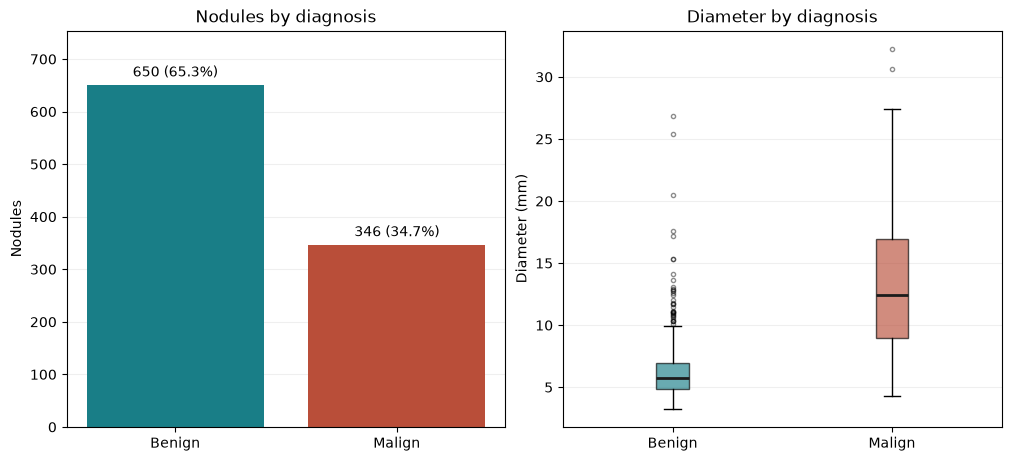

In [4]:
diagnosis_counts = nodules["Diagnosis_group"].value_counts().reindex(diagnosis_order)
diagnosis_summary = diagnosis_counts.rename("Nodules").to_frame()
diagnosis_summary["Share (%)"] = diagnosis_counts / len(nodules) * 100
diameter_summary = (
    nodules.groupby("Diagnosis_group")["diameter_mm"]
    .describe().reindex(diagnosis_order)
    .rename(columns={"25%": "Q1", "50%": "Median", "75%": "Q3"})
)
diameter_summary["IQR"] = diameter_summary["Q3"] - diameter_summary["Q1"]
display(diagnosis_summary.round(1), diameter_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained")
bars = axes[0].bar(diagnosis_order, diagnosis_counts, color=diagnosis_colors)
axes[0].bar_label(bars, labels=[
    f"{count:,} ({count / len(nodules):.1%})" for count in diagnosis_counts
], padding=4)
axes[0].set(title="Nodules by diagnosis", ylabel="Nodules",
            ylim=(0, diagnosis_counts.max() * 1.16))
boxplot = axes[1].boxplot(
    [nodules.loc[nodules["Diagnosis_group"].eq(group), "diameter_mm"]
     for group in diagnosis_order],
    tick_labels=diagnosis_order, patch_artist=True,
    medianprops={"color": "#1B1B1B", "linewidth": 2},
    flierprops={"marker": ".", "alpha": 0.45},
)
for box, color in zip(boxplot["boxes"], diagnosis_colors):
    box.set_facecolor(color)
    box.set_alpha(0.65)
axes[1].set(title="Diameter by diagnosis", ylabel="Diameter (mm)")
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
fig.savefig(results_dir / "consolidated_diagnosis_diameter.png", dpi=220)
plt.show()

There are 650 Benign nodules (65.3%) and 346 Malign nodules (34.7%).
The medians are 5.74 and 12.46 mm, with IQRs of 2.06 and 7.95 mm,
respectively. Malign nodules tend to be larger and have more dispersed
diameters. The overlap limits conclusions about individual nodules.
These are descriptive comparisons, and 234 patients contribute more
than one nodule.

## Morphology and conspicuity

We compare the voting workbook's ordinal scores for spiculation, lobulation,
sphericity, texture, margin and subtlety. Subtlety describes how easy a
nodule is to detect. The code counts each score by diagnosis and divides
by the total number of nodules in that diagnosis group. This normalization
makes the two groups comparable despite their different sizes. Subtlety
and sphericity counts are retained for comparison with the third notebook.

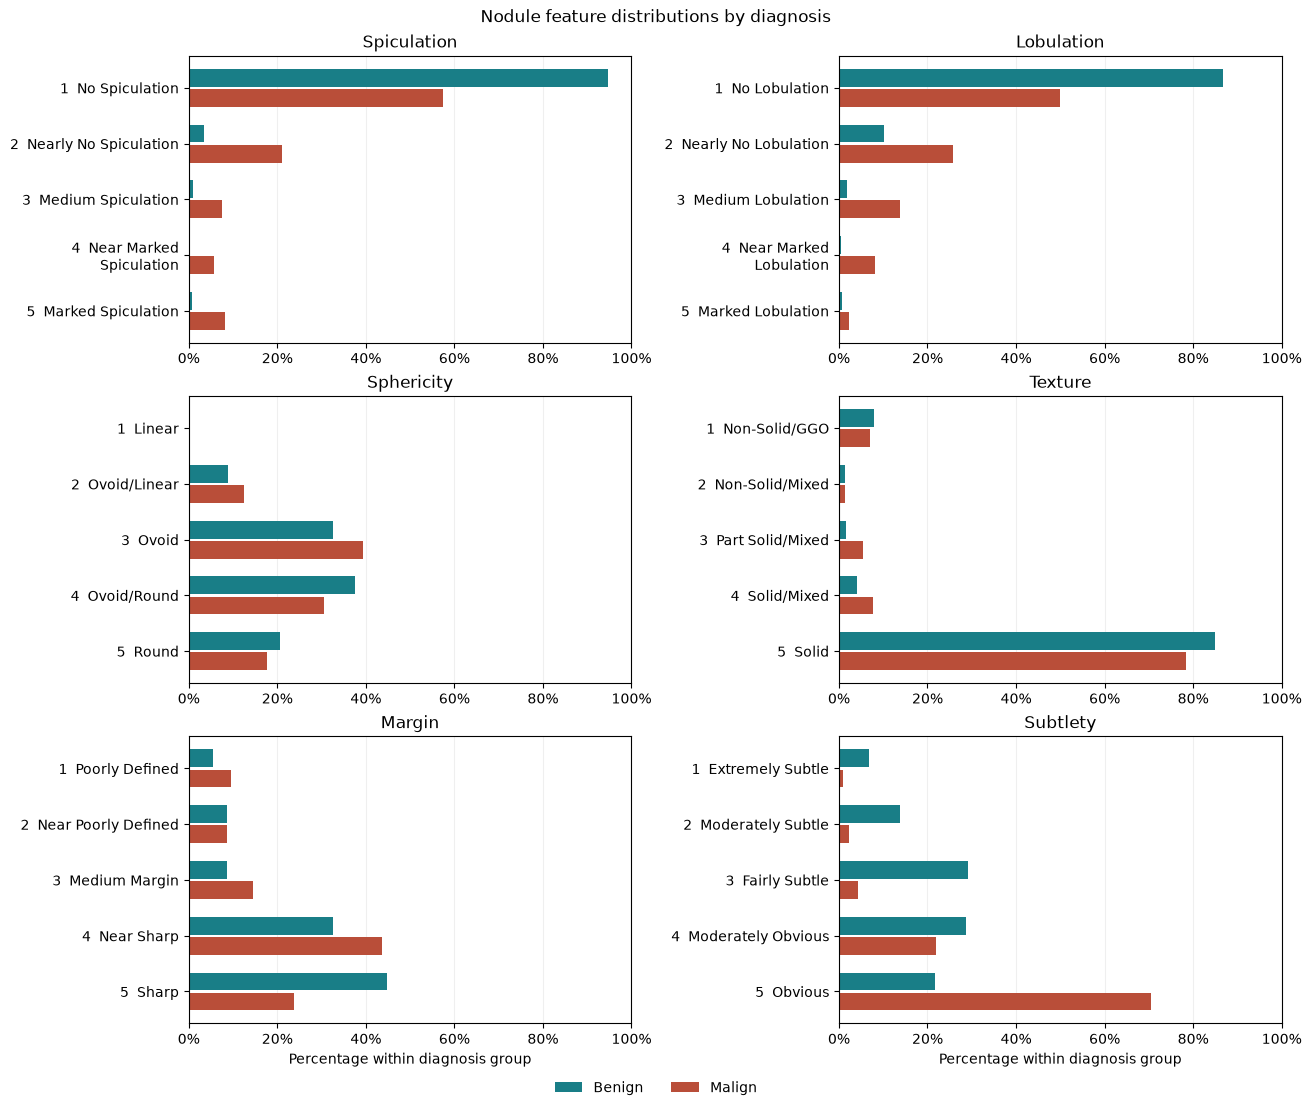

Diagnosis_group,Benign,Malign
Subtlety_value,,
1,44,3
2,89,8
3,190,15
4,186,76
5,141,244


Diagnosis_group,Benign,Malign
Sphericity_value,,
1,2,0
2,58,43
3,212,136
4,244,106
5,134,61


In [5]:
from textwrap import fill

fig, axes = plt.subplots(3, 2, figsize=(13, 11), layout="constrained", sharex=True)
for feature, score_column, ax in zip(features, feature_columns, axes.flat):
    labels = (
        nodules[[score_column, feature]].drop_duplicates()
        .sort_values(score_column).set_index(score_column)[feature]
    )
    if not labels.index.is_unique:
        raise ValueError(f"{feature} has conflicting labels for a score.")
    percentages = (
        pd.crosstab(nodules[score_column], nodules["Diagnosis_group"])
        .reindex(index=labels.index, columns=diagnosis_order, fill_value=0)
        .div(diagnosis_counts, axis="columns") * 100
    )
    positions = np.arange(len(labels))
    for group, color, offset in zip(diagnosis_order, diagnosis_colors, [-0.18, 0.18]):
        ax.barh(positions + offset, percentages[group], height=0.32, color=color, label=group)
    ax.set_yticks(positions, [fill(f"{score}  {label}", 24) for score, label in labels.items()])
    ax.invert_yaxis()
    ax.set(title=feature, xlim=(0, 100))
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.tick_params(axis="x", labelbottom=True)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

for ax in axes[-1]:
    ax.set_xlabel("Percentage within diagnosis group")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=2, frameon=False)
fig.suptitle("Nodule feature distributions by diagnosis")
fig.savefig(results_dir / "consolidated_feature_distributions.png", dpi=220)
plt.show()

for column in ("Subtlety_value", "Sphericity_value"):
    display(pd.crosstab(nodules[column], nodules["Diagnosis_group"]).reindex(columns=diagnosis_order))

The highest subtlety score occurs in 70.5% of Malign nodules and 21.7%
of Benign nodules. Scores above 1 are also more common in the Malign
group for spiculation (42.5% versus 5.4%) and lobulation (50.0% versus
13.2%). Sharp margins are less common in the Malign group (23.7% versus
44.8%). Sphericity and texture show smaller differences. These are
subjective ordinal ratings and may covary with size or with one another.
The distributions do not measure independent contributions.

## Rank correlations

We compute Spearman correlations on 996 voting records. Rank correlations
can describe monotonic associations between continuous diameter, the
ordered feature scores and the binary diagnosis code. The matrix excludes
identifiers, spatial fields, nominal category codes, the malignancy score
and annotation-count fields. The malignancy rating defines the outcome
and would leak outcome information if treated as a predictor.

,Spearman ρ
Diameter,0.694
Subtlety,0.497
Spiculation,0.459
Lobulation,0.412
Margin,-0.189
Sphericity,-0.086
Texture,-0.074


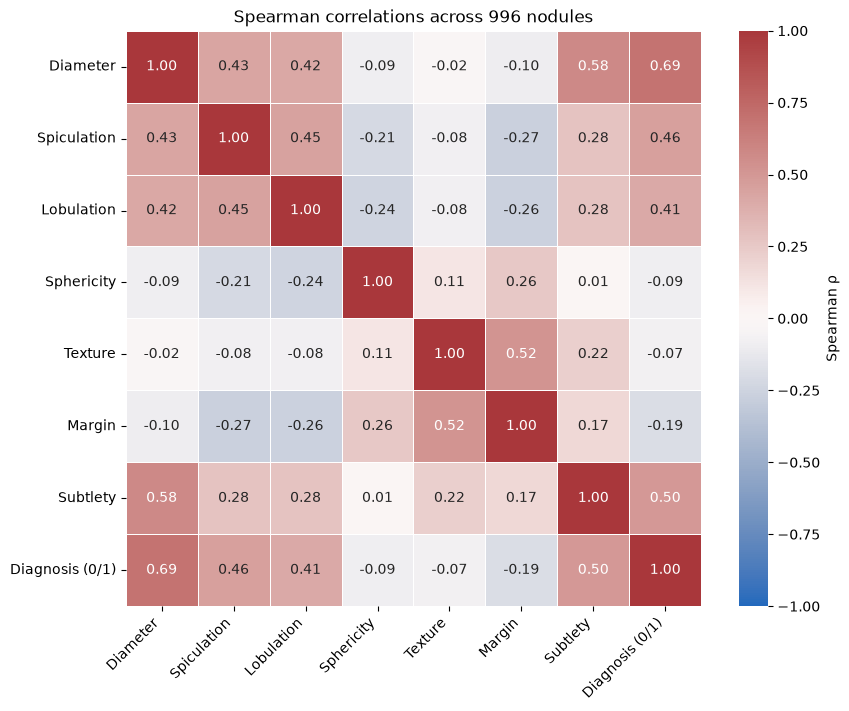

In [6]:
# Use a fixed list of continuous or ordinal features. The diagnosis is the outcome.
correlation_labels = {
    "diameter_mm": "Diameter",
    **dict(zip(feature_columns, features)),
    diagnosis_column: "Diagnosis (0/1)",
}
correlation = (
    nodules[list(correlation_labels)].rename(columns=correlation_labels).corr(method="spearman")
)
diagnosis_correlations = correlation["Diagnosis (0/1)"].drop("Diagnosis (0/1)")
display(diagnosis_correlations.sort_values(key=abs, ascending=False).round(3).to_frame("Spearman ρ"))

fig, ax = plt.subplots(figsize=(9, 7), layout="constrained")
sns.heatmap(
    correlation, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0,
    square=True, linewidths=0.5, cbar_kws={"label": "Spearman ρ"}, ax=ax,
)
ax.set_title("Spearman correlations across 996 nodules")
ax.tick_params(axis="x", labelrotation=45)
for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")
ax.tick_params(axis="y", labelrotation=0)
fig.savefig(results_dir / "consolidated_spearman.png", dpi=220)
plt.show()

Diameter has the largest unadjusted association with the vote-derived
diagnosis (ρ = 0.694), followed by subtlety (0.497), spiculation (0.459)
and lobulation (0.412). Margin is weakly negative (−0.189), as are
sphericity (−0.086) and texture (−0.074). These coefficients describe
relationships in the sample. They do not account for patient clustering,
the relationships among features or any external validation.

## Agreement between annotations

We measure agreement on the same patient–nodule key using the original
annotation scores. The range (maximum minus minimum) measures the span
of ratings, and exact pair agreement counts the share of all within-key
pairs with identical scores. We also count nodules with ratings on
both sides of the suspicious cutoff. To assess the two-series key,
we recompute malignancy-score agreement using only pairs within the
same CT series.

,Nodules with 2+ ratings,Within-nodule pairs,Unanimous nodules,Unanimous (%),Exact pair agreement (%)
Rating,,,,,
Malignancy rating,996,5073,136,13.7,38.1
Spiculation,996,5073,329,33.0,54.5
Lobulation,996,5073,210,21.1,45.1
Sphericity,996,5073,77,7.7,34.1
Texture,996,5073,525,52.7,71.5
Margin,996,5073,145,14.6,41.2


Ratings on both sides of the >3 cutoff: 520 of 996 keys.
Exact malignancy agreement within series: 1,926/5,053 (38.12%).


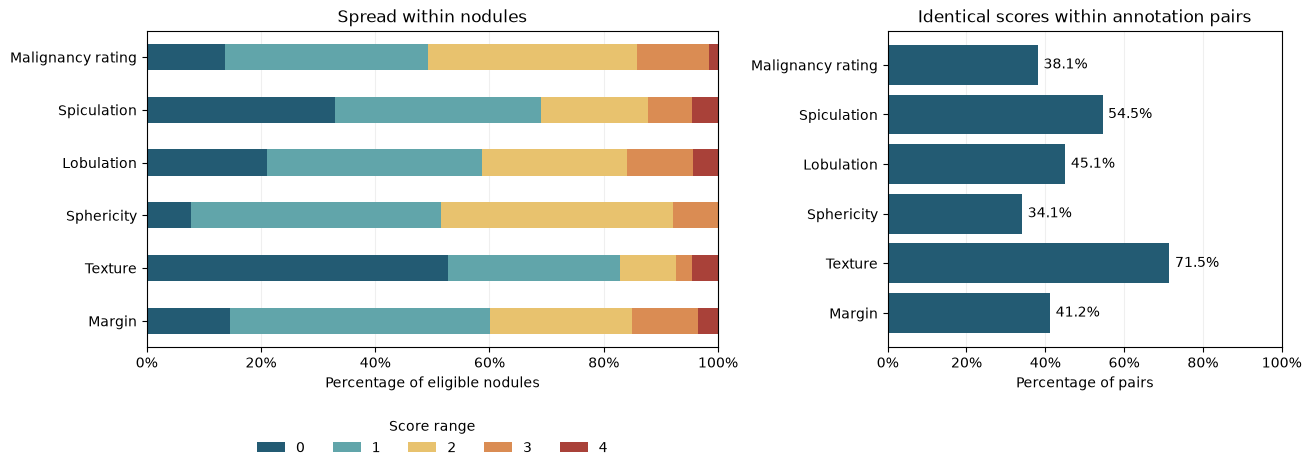

In [7]:
agreement_labels = {"Malignancy_value": "Malignancy rating",
                    **dict(zip(feature_columns[:-1], features[:-1]))}
agreement_rows = []
spread_counts = {}
for column, label in agreement_labels.items():
    rated = annotations.dropna(subset=[column])
    by_nodule = rated.groupby(nodule_keys)[column].agg(["count", "min", "max"])
    eligible = by_nodule.loc[by_nodule["count"].ge(2)]
    spread = eligible["max"] - eligible["min"]
    if not spread.isin(range(5)).all():
        raise ValueError(f"Unexpected score range for {column}.")
    counts_per_score = rated.groupby(nodule_keys + [column]).size()
    exact_pairs = (counts_per_score * (counts_per_score - 1) // 2).sum()
    total_pairs = (eligible["count"] * (eligible["count"] - 1) // 2).sum()
    spread_counts[label] = spread.value_counts().reindex(range(5), fill_value=0)
    agreement_rows.append({
        "Rating": label,
        "Nodules with 2+ ratings": len(eligible),
        "Within-nodule pairs": total_pairs,
        "Unanimous nodules": int(spread.eq(0).sum()),
        "Unanimous (%)": spread.eq(0).mean() * 100,
        "Exact pair agreement (%)": exact_pairs / total_pairs * 100,
    })
agreement = pd.DataFrame(agreement_rows).set_index("Rating")
display(agreement.round(1))


split = vote_counts["sum"].gt(0) & vote_counts["sum"].lt(vote_counts["size"])
print(f"Ratings on both sides of the >3 cutoff: {split.sum():,} of {len(split):,} keys.")

series_keys = nodule_keys + ["seriesuid"]
series_sizes = annotations.groupby(series_keys).size()
series_scores = annotations.groupby(series_keys + [rating]).size()
series_pairs = (series_sizes * (series_sizes - 1) // 2).sum()
series_exact = (series_scores * (series_scores - 1) // 2).sum()
print(f"Exact malignancy agreement within series: {series_exact:,}/{series_pairs:,} "
      f"({series_exact / series_pairs:.2%}).")

spread_table = pd.DataFrame(spread_counts).T
spread_pct = spread_table.div(spread_table.sum(axis=1), axis=0) * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), layout="constrained",
                         gridspec_kw={"width_ratios": [1.45, 1]})
spread_pct.plot.barh(
    stacked=True, color=["#235B73", "#61A5AA", "#E8C26E", "#DA8C53", "#A94139"],
    ax=axes[0], legend=False,
)
axes[0].legend(title="Score range", ncols=5, loc="upper center", bbox_to_anchor=(0.5, -0.19),
               frameon=False)
axes[0].set(title="Spread within nodules", xlabel="Percentage of eligible nodules", ylabel="")
pair_bars = axes[1].barh(agreement.index, agreement["Exact pair agreement (%)"], color="#235B73")
axes[1].bar_label(pair_bars, fmt="%.1f%%", padding=4)
axes[1].set(title="Identical scores within annotation pairs", xlabel="Percentage of pairs")
for ax in axes:
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
fig.savefig(results_dir / "consolidated_agreement.png", dpi=220)
plt.show()

Malignancy scores are unanimous for 136 nodules (13.7%), and 1,934 of
5,073 annotation pairs agree exactly (38.12%). In 520 nodules (52.2%),
scores straddle the suspicious cutoff. Restricting to within-series
pairs gives 1,926 of 5,053 (38.12% to two decimal places). Texture has the
highest exact pair agreement (71.5%) and sphericity the lowest (34.1%)
among the ratings displayed.

The pair measure gives greater weight to nodules with more annotations
and is not adjusted for chance. `anotation_id` identifies an annotation.
There is no persistent reader identifier, so we cannot establish
reader-specific reliability or identify repeated ratings by a reader.

## Image inventory and segmentation overlays

We match cropped VOI files to metadata using the patient and nodule in
their filename. Full CT images are identified by patient and matched to
nodule-specific masks. We count available and absent pairs before
selecting an example with both types of image for each diagnosis.
NiBabel checks image–mask shape and affine alignment, reorients the pair
to canonical axes, and displays the axial slice with the largest mask area.

,Metadata,CT_pairs,VOI_pairs,Without CT pair,Without VOI pair
Diagnosis_group,,,,,
Benign,650,2,650,648,0
Malign,346,4,344,342,2


Full CT volumes: 3. Full CT masks: 6.
VOI masks without images: LIDC-IDRI-1002_R_1.nii.gz, LIDC-IDRI-1002_R_2.nii.gz
VOI images without masks: None


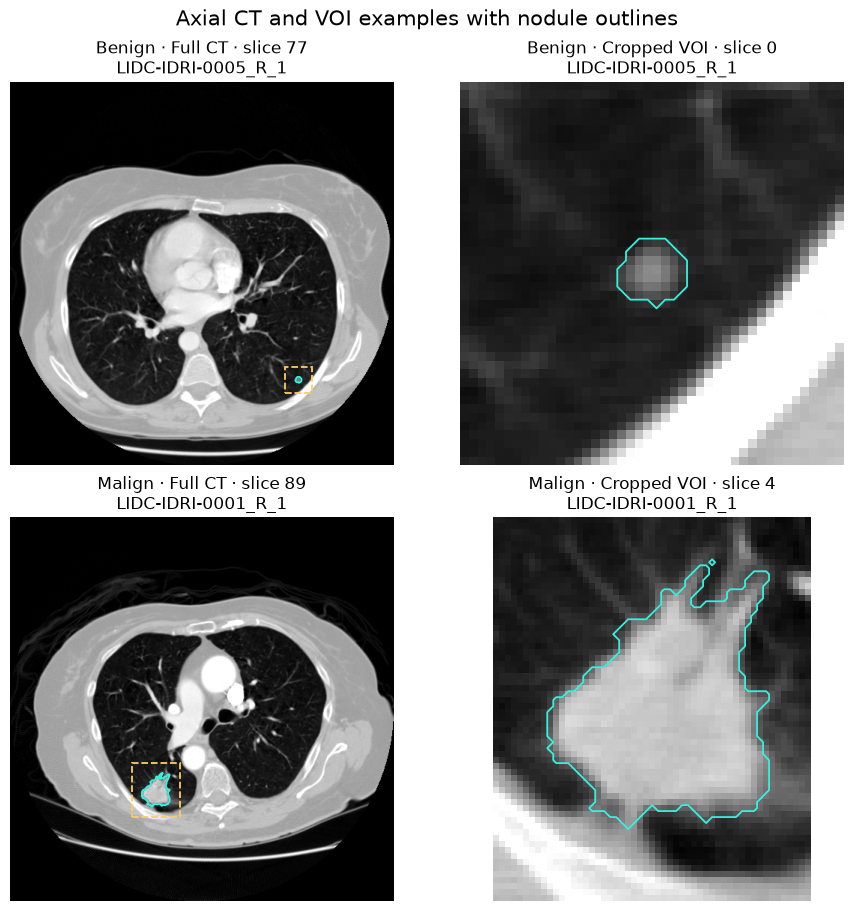

In [8]:
imaging = nodules[nodule_keys + ["Diagnosis_group"]].copy()
imaging["nodule_file"] = (
    imaging["patient_id"] + "_R_" + imaging["nodule_id"].astype(str) + ".nii.gz"
)
ct_images, ct_masks, voi_images, voi_masks = [
    {path.name for path in folder.glob("*.nii.gz") if path.is_file()} for folder in image_folders
]
imaging["has_ct_pair"] = (
    (imaging["patient_id"] + ".nii.gz").isin(ct_images) & imaging["nodule_file"].isin(ct_masks)
)
imaging["has_voi_pair"] = imaging["nodule_file"].isin(voi_images & voi_masks)
coverage = imaging.groupby("Diagnosis_group").agg(
    Metadata=("nodule_file", "size"), CT_pairs=("has_ct_pair", "sum"),
    VOI_pairs=("has_voi_pair", "sum"),
).reindex(diagnosis_order)
coverage["Without CT pair"] = coverage["Metadata"] - coverage["CT_pairs"]
coverage["Without VOI pair"] = coverage["Metadata"] - coverage["VOI_pairs"]
display(coverage)
print(f"Full CT volumes: {len(ct_images)}. Full CT masks: {len(ct_masks)}.")
print("VOI masks without images:", ", ".join(sorted(voi_masks - voi_images)) or "None")
print("VOI images without masks:", ", ".join(sorted(voi_images - voi_masks)) or "None")

def plot_masked_slice(ax, image_path, mask_path, *, mark_location=False):
    image = nib.load(image_path)
    mask = nib.load(mask_path)
    if (len(image.shape) != 3 or image.shape != mask.shape
            or not np.allclose(image.affine, mask.affine, rtol=0, atol=1e-4)):
        raise ValueError(f"Image and mask grids do not match: {image_path.name}, {mask_path.name}")
    image, mask = map(nib.as_closest_canonical, (image, mask))
    mask_data = np.asarray(mask.dataobj) > 0
    area_per_slice = np.count_nonzero(mask_data, axis=(0, 1))
    if not area_per_slice.any():
        raise ValueError(f"Empty segmentation mask: {mask_path.name}")
    slice_index = int(area_per_slice.argmax())
    mask_slice = mask_data[:, :, slice_index].T
    image_slice = np.asarray(image.dataobj[:, :, slice_index]).T.copy()
    dx, dy = image.header.get_zooms()[:2]
    ax.imshow(image_slice, cmap="gray", origin="lower", vmin=-1000, vmax=400, aspect=dy / dx)
    # Pad to draw a closed contour even when the segmentation touches the edge.
    ax.contour(
        np.arange(-1, mask_slice.shape[1] + 1), np.arange(-1, mask_slice.shape[0] + 1),
        np.pad(mask_slice, 1), levels=[0.5], colors=["#35F1DE"], linewidths=1.3,
    )
    ax.set(xlim=(-0.5, mask_slice.shape[1] - 0.5), ylim=(-0.5, mask_slice.shape[0] - 0.5))
    if mark_location:
        rows, cols = np.where(mask_slice)
        padding = 14
        ax.add_patch(Rectangle(
            (cols.min() - padding, rows.min() - padding),
            np.ptp(cols) + 2 * padding, np.ptp(rows) + 2 * padding,
            edgecolor="#FFCC61", facecolor="none", linewidth=1.3, linestyle="--",
        ))
    ax.set_axis_off()
    return slice_index

fig, axes = plt.subplots(2, 2, figsize=(9, 9), layout="constrained")
for row, group in enumerate(diagnosis_order):
    group_images = imaging.loc[imaging["Diagnosis_group"].eq(group)].sort_values(nodule_keys)
    both_pairs = group_images.loc[group_images["has_ct_pair"] & group_images["has_voi_pair"]]
    for col, (root, pair_column, name) in enumerate(
        [(ct_root, "has_ct_pair", "Full CT"), (voi_root, "has_voi_pair", "Cropped VOI")]
    ):
        ax = axes[row, col]
        candidates = both_pairs if not both_pairs.empty else group_images.loc[group_images[pair_column]]
        if candidates.empty:
            ax.text(0.5, 0.5, f"No matched {name} pair\nfor {group}", ha="center", va="center")
            ax.set_axis_off()
            continue
        case = candidates.iloc[0]
        mask_name = case["nodule_file"]
        image_name = case["patient_id"] + ".nii.gz" if col == 0 else mask_name
        index = plot_masked_slice(
            ax, root / "image" / image_name, root / "nodule_mask" / mask_name,
            mark_location=(col == 0),
        )
        ax.set_title(f"{group} · {name} · slice {index}\n{mask_name.removesuffix('.nii.gz')}")
fig.suptitle("Axial CT and VOI examples with nodule outlines", fontsize=15)
fig.savefig(results_dir / "consolidated_ct_voi_examples.png", dpi=220)
plt.show()

The supplied sample contains three full CT volumes and six usable
full-CT mask pairs (two Benign and four Malign), so 990 metadata keys
have no matched full CT pair in this checkout. Cropped VOI coverage is
994 of 996 keys. The two missing VOI images are
`LIDC-IDRI-1002_R_1.nii.gz` and `LIDC-IDRI-1002_R_2.nii.gz`, both
labeled Malign. Their masks and metadata are present. No image is
available in this checkout to verify those two masks. The two missing
files do not reduce the tabular cohort. `AcqParams.xlsx`, mentioned
in the course description, is absent from the supplied project sample,
so acquisition parameters from that workbook could not be compared.

The overlays illustrate the pairing and display method. They are
selected from the few nodules with both image types and should not be
used to infer image-level performance or prevalence.

## Figures for the project report

The group-count and diameter panel, six feature distributions, Spearman
heatmap, annotation agreement chart and CT/VOI examples convey different
results. The table of diameter by unique modal rating preserves the
original analysis without repeating the main diameter plot. The report
uses the same workbook definitions and denominators as this notebook.

## Radiomics extraction and model cohort

The team extracted 107 original-image descriptors with PyRadiomics from 994
matched cropped images and binary masks. These describe shape, voxel intensity,
and texture. The extraction notebook records its Python 3.11 and PyRadiomics
versions, settings, matching code and three-dimensional reconstruction. This
notebook uses the exported features as inputs. The extraction step remains in
`Radiomics.ipynb`.

The model cohort excludes the two missing cropped images and the patient–nodule
key spanning two series. The following checks reconcile all model labels
against the 996-record workbook, audit the feature values, and verify that
the saved training, validation and test files partition the model cohort
without patient overlap.

,Descriptors
glcm,24
firstorder,18
glrlm,16
glszm,16
shape,14
gldm,14
ngtdm,5


,Nodules,Patients,Benign,Suspicious
training,595,328,390,205
validation,198,111,129,69
testing,200,112,131,69


Excluded workbook diagnosis
patient_id     nodule_id                             
LIDC-IDRI-0332 1                                    1
LIDC-IDRI-1002 1                                    1
               2                                    1

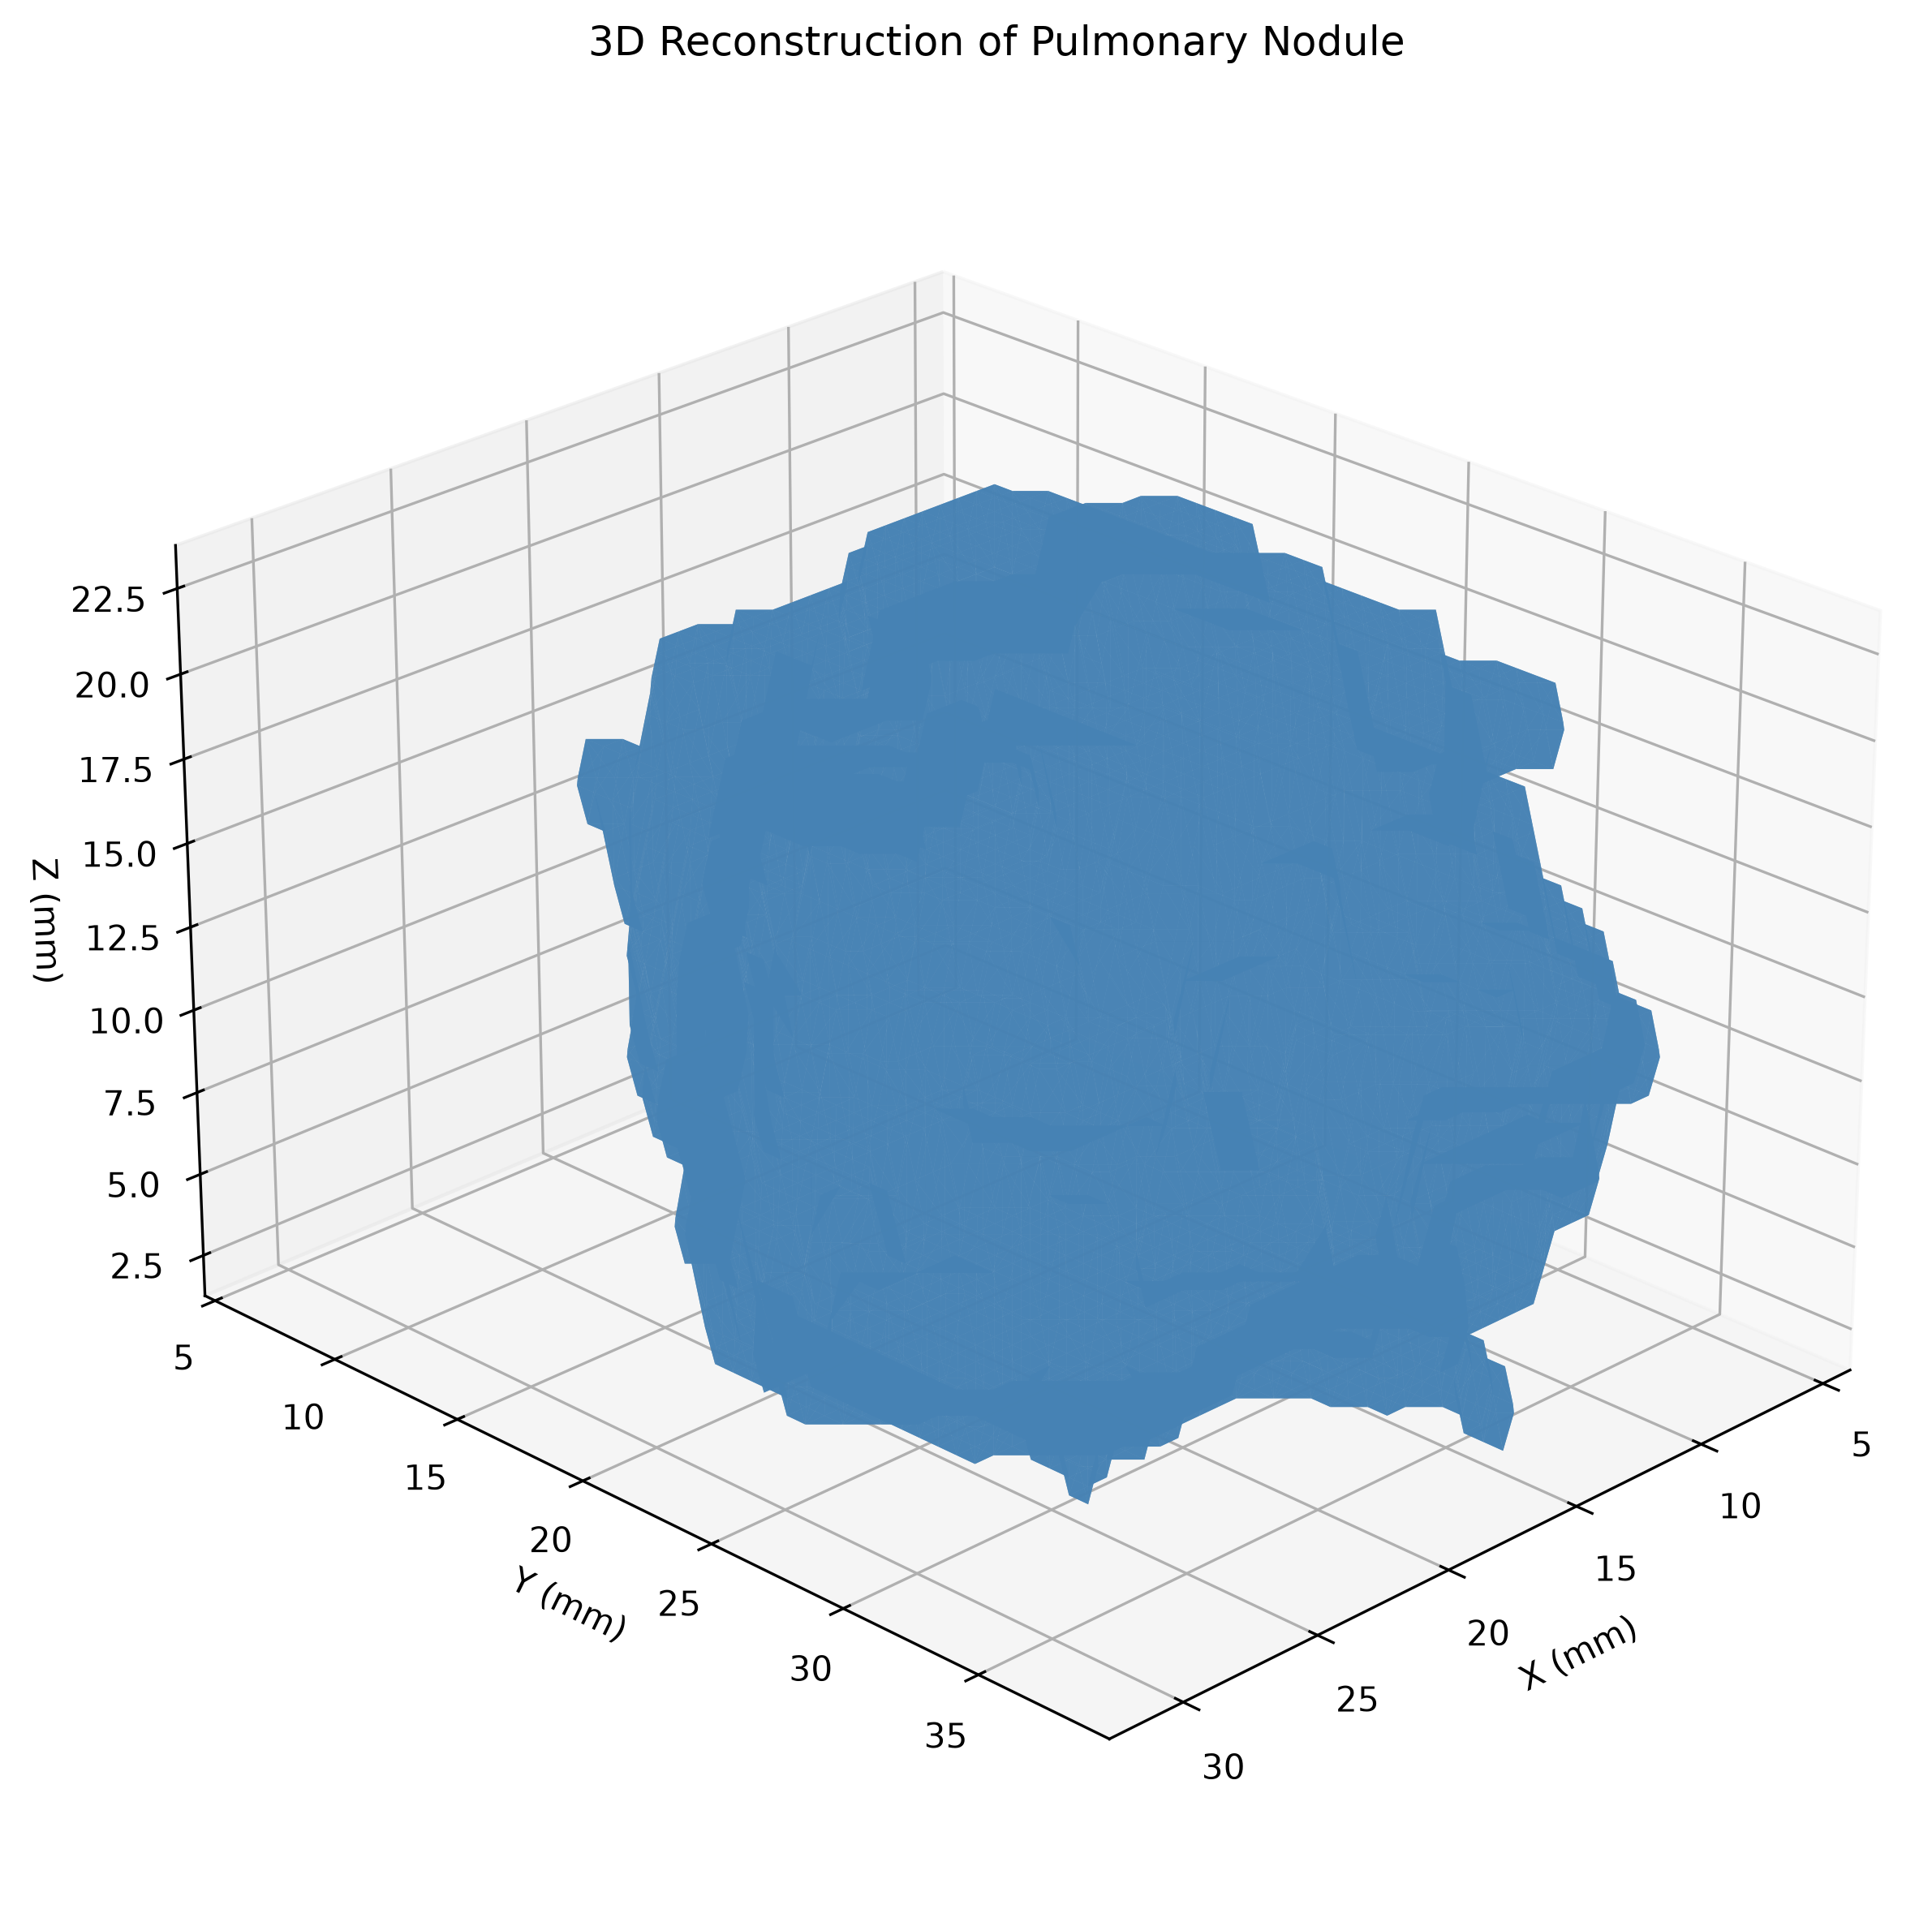

In [9]:
from itertools import combinations

from IPython.display import Image, display

target = "malignancy_label"
extracted = pd.read_csv(results_dir / "radiomics_features.csv")
model_cohort = pd.read_csv(results_dir / "classification_dataset.csv")
splits = {
    name: pd.read_csv(results_dir / f"{name}_dataset.csv")
    for name in ("training", "validation", "testing")
}
descriptors = [column for column in model_cohort if column.startswith("original_")]
assert (len(extracted), len(model_cohort), len(descriptors)) == (994, 993, 107)
for frame in (extracted, model_cohort, *splits.values()):
    assert not frame[nodule_keys].isna().any().any()
    assert not frame.duplicated(nodule_keys).any()
    assert np.isfinite(frame[descriptors].to_numpy()).all()
for first, second in combinations(splits.values(), 2):
    assert set(first.patient_id).isdisjoint(second.patient_id)

model_indexed = model_cohort.set_index(nodule_keys).sort_index()
split_indexed = pd.concat(splits.values()).set_index(nodule_keys).sort_index()
pd.testing.assert_frame_equal(model_indexed, split_indexed)
pd.testing.assert_frame_equal(
    model_indexed[descriptors],
    extracted.set_index(nodule_keys).loc[model_indexed.index, descriptors],
)
assert model_indexed[target].eq(observed_diagnosis.reindex(model_indexed.index)).all()

family_counts = pd.Series([column.split("_", 2)[1] for column in descriptors])
display(family_counts.value_counts().rename("Descriptors").to_frame())
display(pd.DataFrame.from_dict({
    name: {
        "Nodules": len(frame), "Patients": frame.patient_id.nunique(),
        "Benign": frame[target].eq(0).sum(), "Suspicious": frame[target].eq(1).sum(),
    } for name, frame in splits.items()
}, orient="index"))
display(observed_diagnosis.loc[~observed_diagnosis.index.isin(model_indexed.index)]
        .rename("Excluded workbook diagnosis").to_frame())
display(Image(filename=str(results_dir / "nodule_3d_reconstruction.png"), width=640))

The model cohort contains 650 benign-coded and 343 suspicious nodules. All
three excluded keys have a suspicious label, so the benign count is the same
as in the metadata analysis. The 595 training, 198 validation and 200 test
nodules come from 328, 111 and 112 disjoint patients. The mesh shows an
example of the supplied segmentation from which geometric features are
derived. Its shape depends on the mask and image sampling.

## PCA and K-means on the development cohort

We standardize the 107 descriptors and fit PCA on the original 793
development cases, which comprise the later training and validation sets.
We cluster the components that explain at least 95% of the variance and
compare silhouette scores and adjusted Rand indices (ARI). Silhouette
measures separation in feature space, while ARI measures agreement with
the supplied labels. The final classifiers use the original descriptors.

,Silhouette,ARI
Clusters,,
2,0.302,0.388
3,0.364,0.288
4,0.222,0.244
5,0.240,0.151
6,0.245,0.196


Workbook label,0,1
Two-cluster assignment,,
0,39,168
1,480,106


Components for 90% and 95% of variance: 10, 15


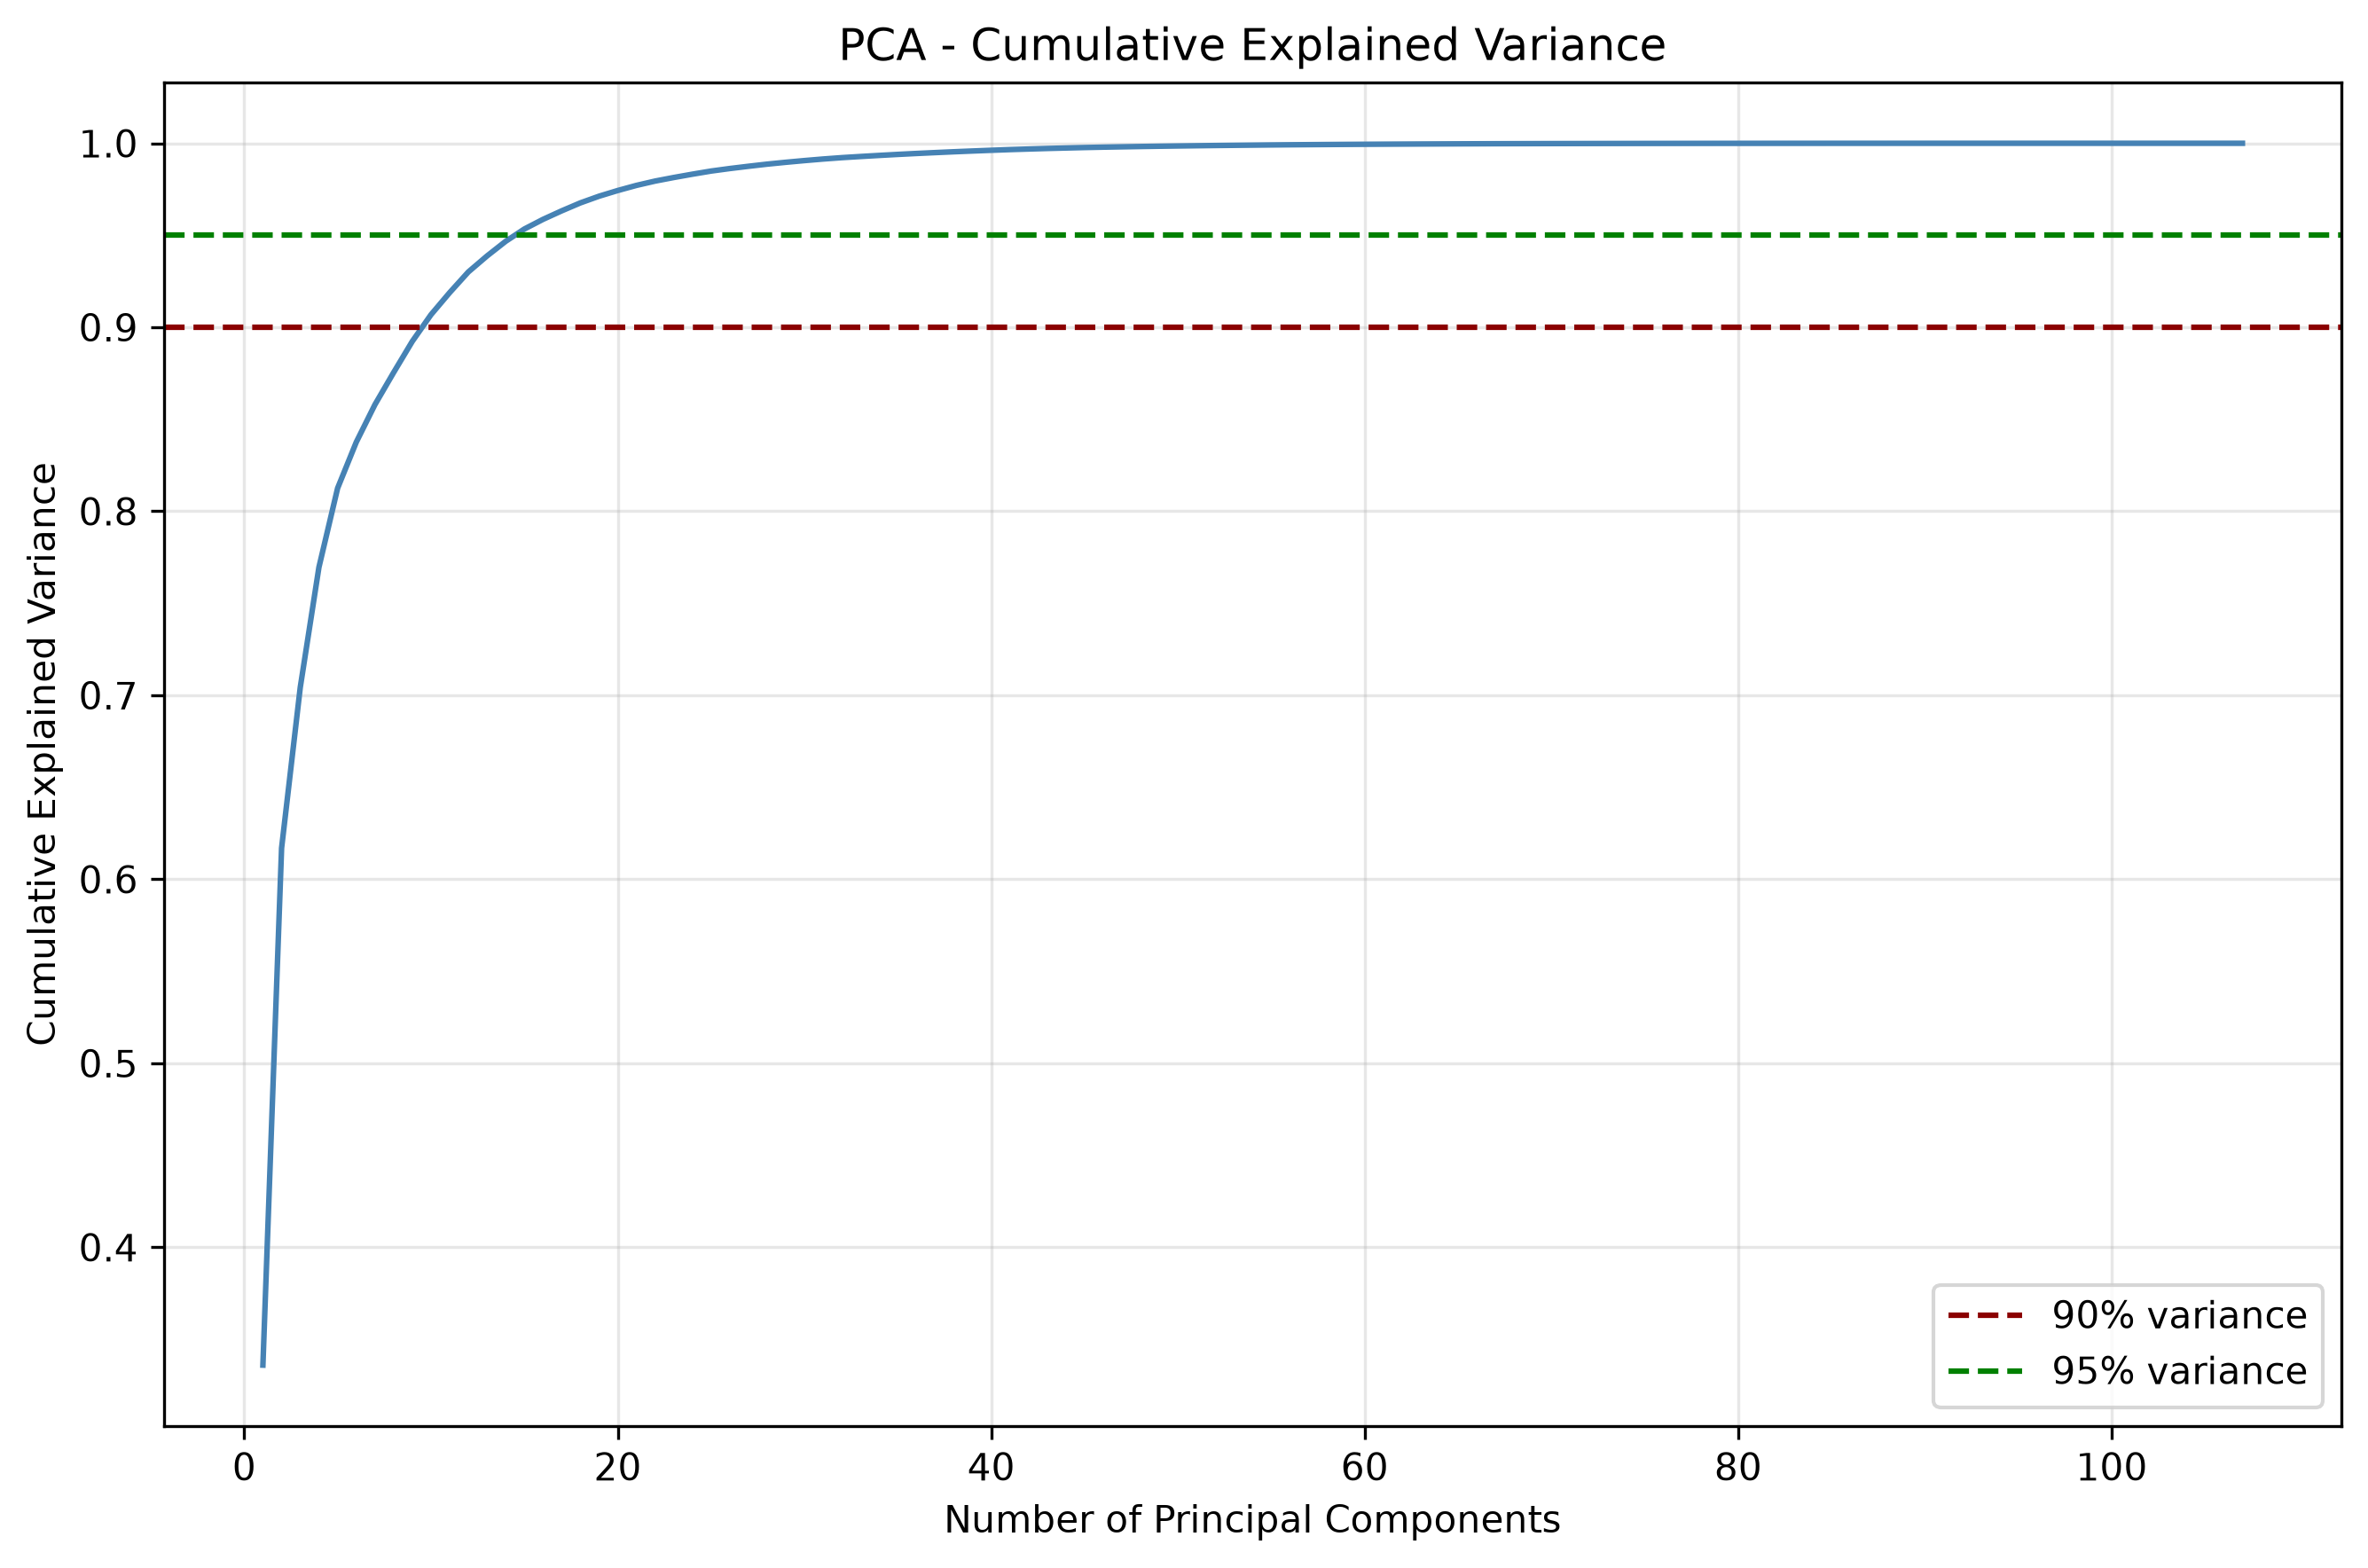

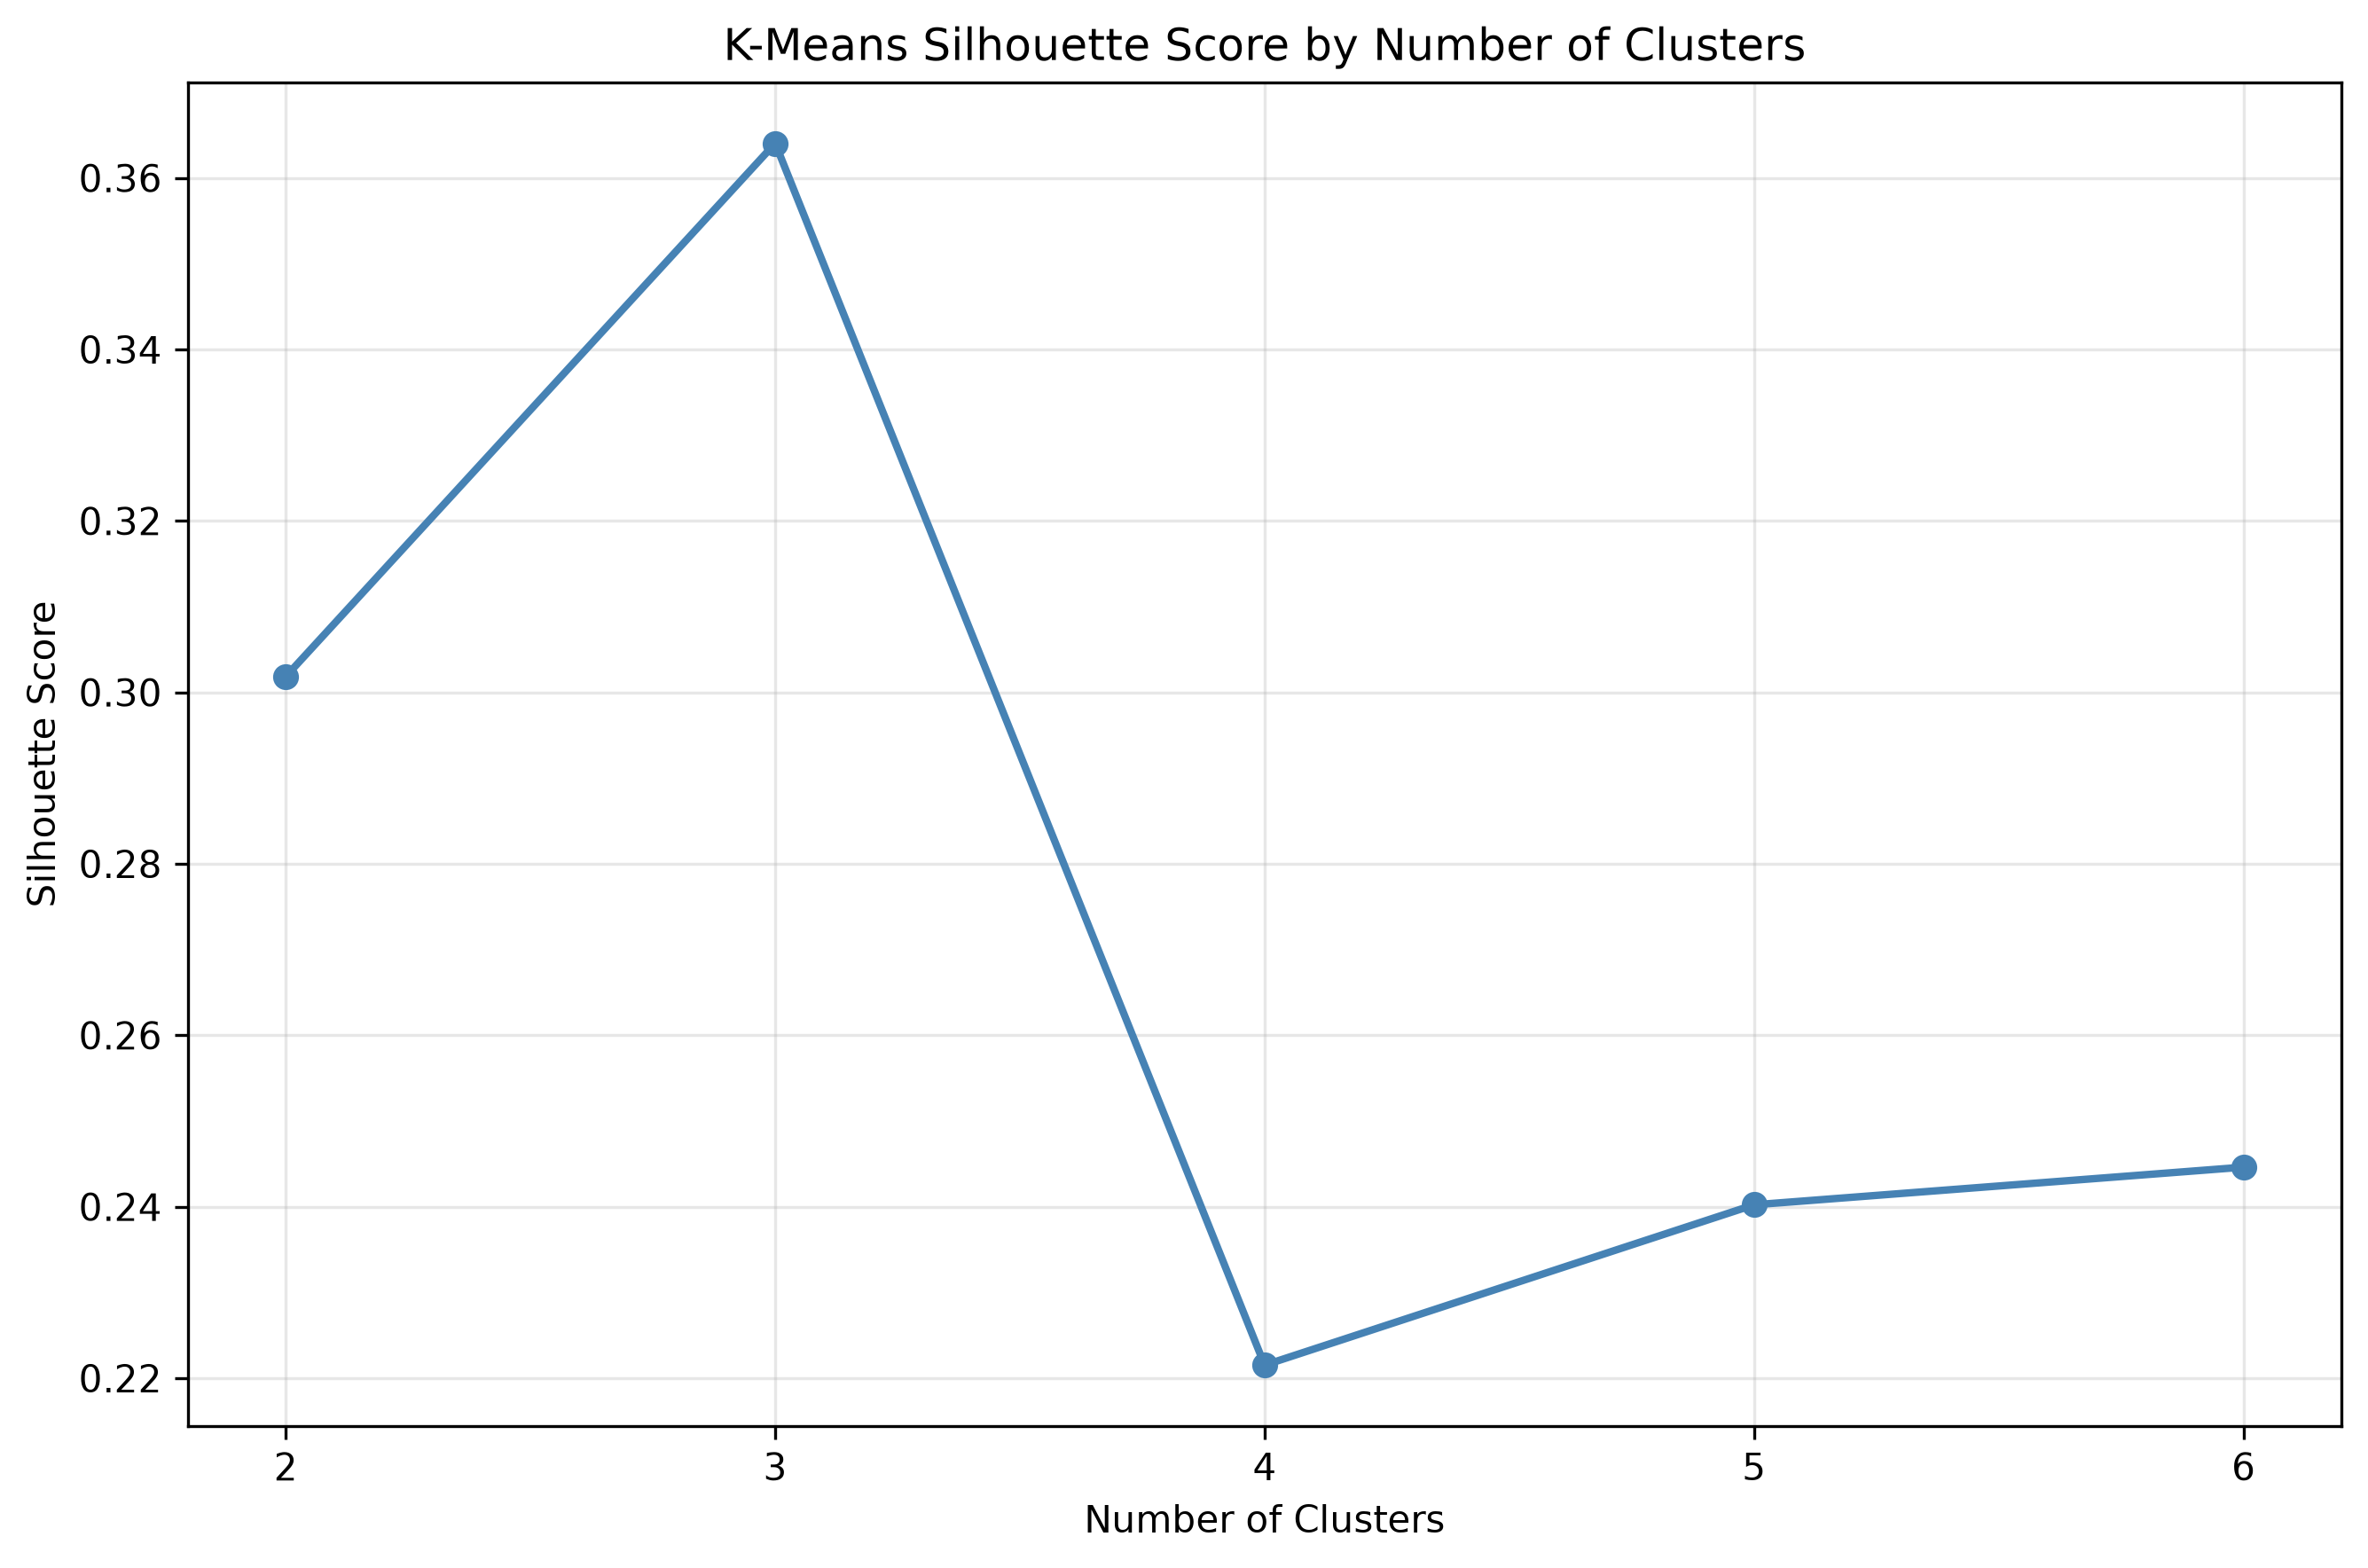

In [10]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

test = splits["testing"]
development = model_cohort.loc[~model_cohort.patient_id.isin(test.patient_id)]
assert len(development) == 793
with threadpool_limits(limits=1):
    pca = PCA()
    projected = pca.fit_transform(StandardScaler().fit_transform(development[descriptors]))
    variance = np.cumsum(pca.explained_variance_ratio_)
    count_90, count_95 = np.searchsorted(variance, [0.90, 0.95]) + 1
    reduced = projected[:, :count_95]
    clusters = {}
    scores = []
    for k in range(2, 7):
        assignment = KMeans(n_clusters=k, random_state=42, n_init=20).fit_predict(reduced)
        clusters[k] = assignment
        scores.append({
            "Clusters": k, "Silhouette": silhouette_score(reduced, assignment),
            "ARI": adjusted_rand_score(development[target], assignment),
        })
clustering = pd.DataFrame(scores).set_index("Clusters")
display(clustering.round(3))
display(pd.crosstab(clusters[2], development[target].to_numpy(),
                   rownames=["Two-cluster assignment"], colnames=["Workbook label"]))
print(f"Components for 90% and 95% of variance: {count_90}, {count_95}")
display(Image(filename=str(results_dir / "pca_explained_variance.png"), width=560))
display(Image(filename=str(results_dir / "kmeans_silhouette_comparison.png"), width=560))

Ten components explain at least 90% of standardized variance and fifteen
explain at least 95%. Three clusters give the best silhouette among the
tested choices (0.364), while two clusters align better with the binary
label (ARI 0.388 versus 0.288 for three). Neither partition recovers the
binary labels cleanly. The exercise describes redundancy and cluster
structure in the development sample.

## Reproduction of the team's supervised comparison

We fit the team's class-weighted 200-tree Random Forest and scaled,
class-weighted RBF SVM on the saved 595 training cases. Candidate comparison
uses the 198 validation cases. The selected Random Forest is then evaluated
on the saved 200-case test partition without refitting. The team had already
inspected those 200 cases during its preliminary 793/200 experiment.

Reproduction with scikit-learn 1.9.1


,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC
Random Forest,0.833,0.845,0.709,0.884,0.787,0.923
SVM,0.818,0.837,0.681,0.899,0.775,0.916


,Reproduced,Team export
Accuracy,0.900000,0.900000
Balanced Accuracy,0.885939,0.885939
Precision,0.865672,0.865672
Recall,0.840580,0.840580
F1,0.852941,0.852941
ROC-AUC,0.932570,0.932625


,Predicted benign,Predicted suspicious
Actual benign,122,9
Actual suspicious,11,58


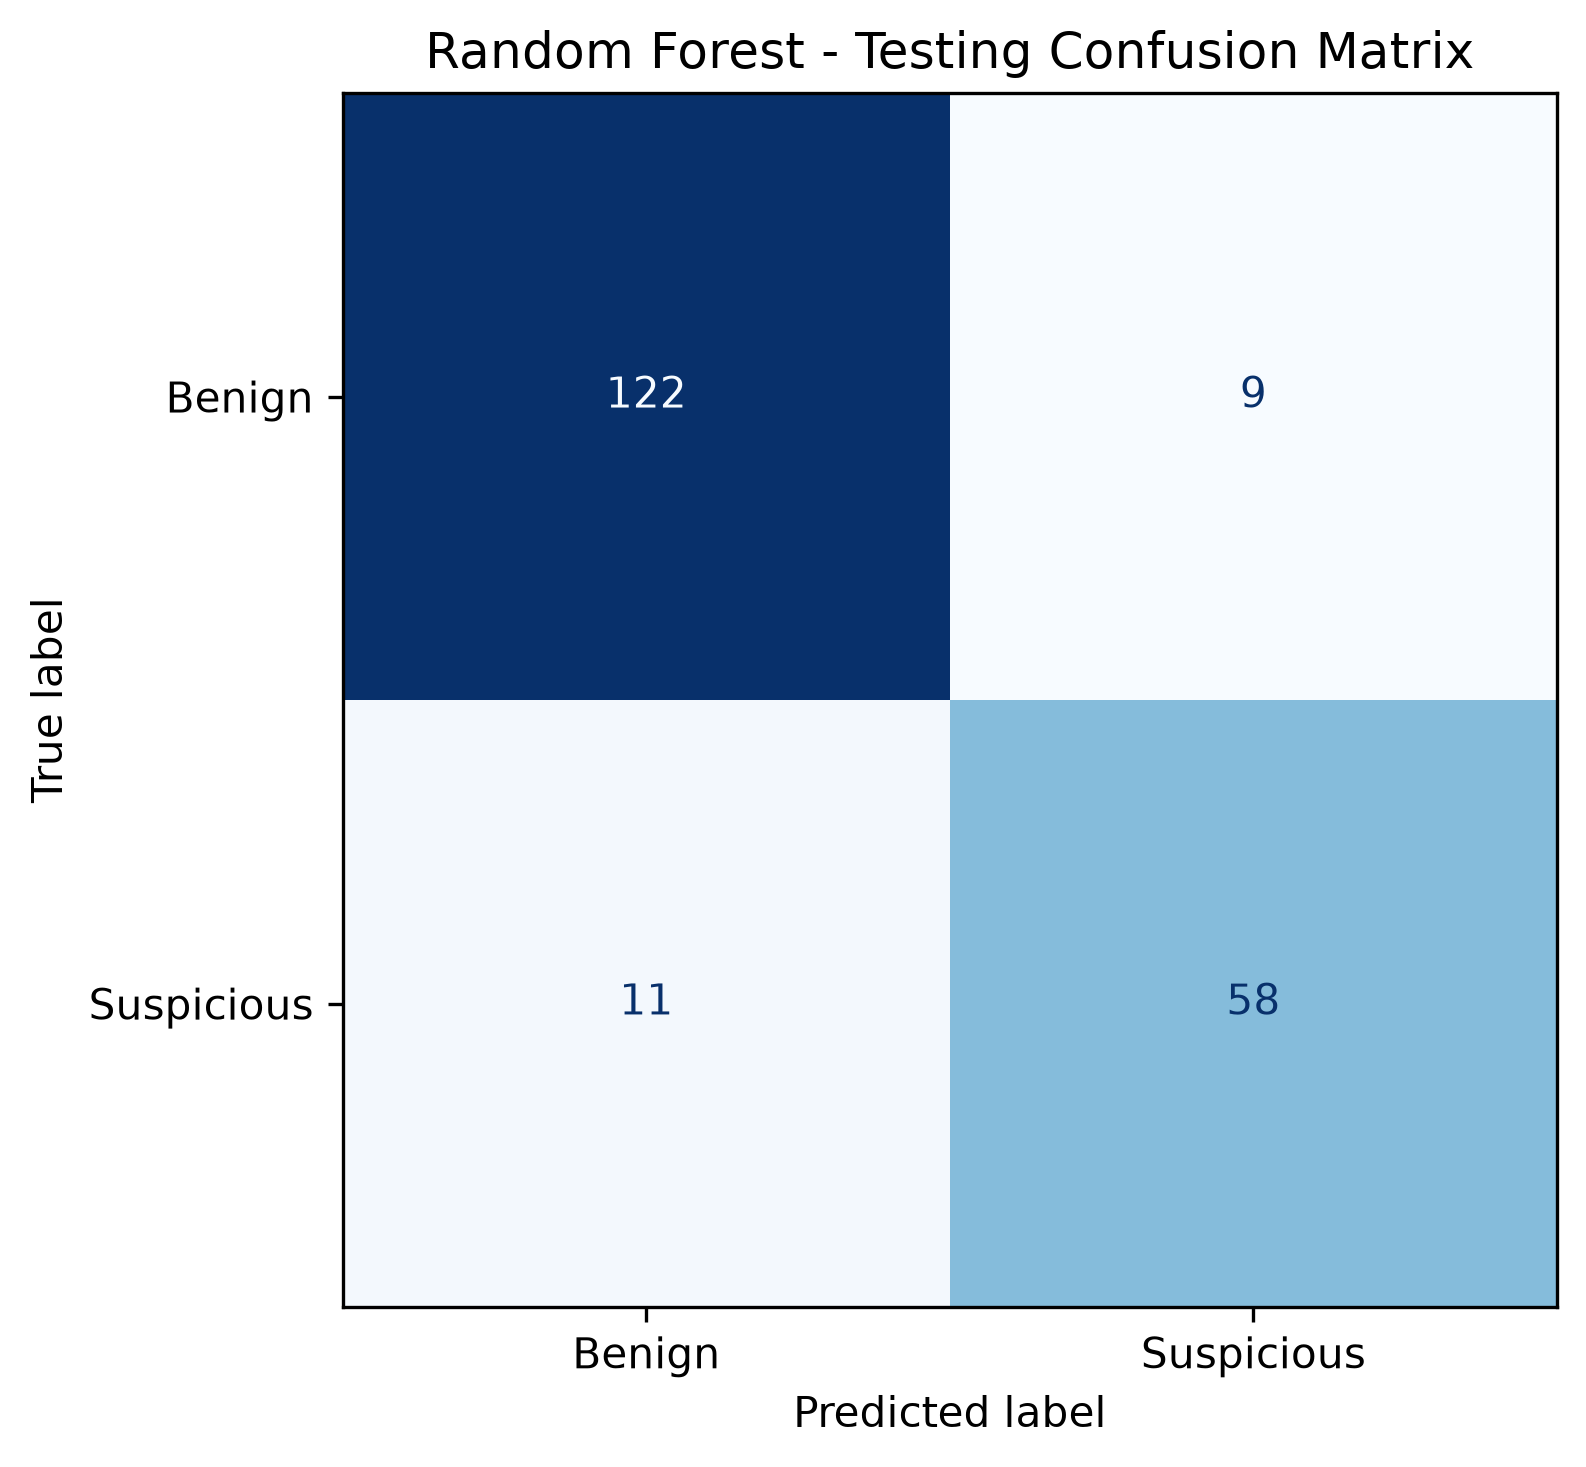

In [11]:
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC

train, validation = splits["training"], splits["validation"]
forest = RandomForestClassifier(
    n_estimators=200, class_weight="balanced", random_state=42, n_jobs=1,
)
svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, class_weight="balanced"))
for estimator in (forest, svm):
    estimator.fit(train[descriptors], train[target])


def metrics(labels, predictions, scores):
    return {
        "Accuracy": accuracy_score(labels, predictions),
        "Balanced Accuracy": balanced_accuracy_score(labels, predictions),
        "Precision": precision_score(labels, predictions, zero_division=0),
        "Recall": recall_score(labels, predictions, zero_division=0),
        "F1": f1_score(labels, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(labels, scores),
    }


X_validation, X_test = validation[descriptors], test[descriptors]
rf_val = forest.predict(X_validation), forest.predict_proba(X_validation)[:, 1]
svm_val = svm.predict(X_validation), svm.decision_function(X_validation)
rf_test = forest.predict(X_test), forest.predict_proba(X_test)[:, 1]

validation_metrics = pd.DataFrame({
    "Random Forest": metrics(validation[target], *rf_val),
    "SVM": metrics(validation[target], *svm_val),
}).T
test_metrics = pd.Series(metrics(test[target], *rf_test), name="Reproduced")
reference_validation = pd.read_csv(results_dir / "model_validation_comparison.csv").set_index("Model")
reference_test = pd.read_csv(results_dir / "random_forest_testing_confidence_intervals.csv").set_index("Metric")
reference_test = reference_test.rename(index={"F1-score": "F1"})
assert np.allclose(validation_metrics[reference_validation.columns], reference_validation)
assert np.allclose(test_metrics.drop("ROC-AUC"), reference_test.loc[test_metrics.drop("ROC-AUC").index, "Testing Score"])

print(f"Reproduction with scikit-learn {sklearn.__version__}")
display(validation_metrics.round(3))
display(pd.concat([test_metrics, reference_test["Testing Score"].rename("Team export")], axis=1).round(6))
display(pd.DataFrame(
    confusion_matrix(test[target], rf_test[0], labels=[0, 1]),
    index=["Actual benign", "Actual suspicious"], columns=["Predicted benign", "Predicted suspicious"],
))
display(Image(filename=str(results_dir / "random_forest_testing_confusion_matrix.png"), width=500))

Validation F1 was 0.787 for Random Forest and 0.775 for SVM. SVM recalled
slightly more suspicious cases on validation (0.899 versus 0.884). The saved
tuning runs did not improve validation F1, so the team selected the
original Random Forest. On test it correctly classified 180 of 200 nodules
and missed 11 of the 69 suspicious cases. Accuracy was 0.900, F1 was 0.853
and ROC-AUC was 0.933 at report precision. The rerun matches all
threshold-based metrics. The small ROC-AUC difference is visible in the
side-by-side output.

## Patient bootstrap and saved exploratory experiments

We resample test patients with replacement 1,000 times and carry all
their nodules together in each draw. The fitted model and its predictions
are fixed. Percentile intervals describe sampling uncertainty conditional
on this fit and the available test patients. The saved paired validation
bootstrap gives both candidates the same sampled patients in each draw.

,Reproduced lower,Reproduced upper,CI Lower,CI Upper
Accuracy,0.853,0.946,0.853,0.946
Balanced Accuracy,0.831,0.939,0.831,0.939
Precision,0.770,0.947,0.770,0.947
Recall,0.743,0.924,0.743,0.924
F1,0.774,0.917,0.774,0.917
ROC-AUC,0.885,0.974,0.885,0.974


,Metric,Difference,Difference CI Lower,Difference CI Upper
0,Accuracy,0.015,-0.028,0.058
1,Precision,0.028,-0.029,0.092
2,Recall,-0.014,-0.078,0.048
3,F1,0.012,-0.039,0.063
4,ROC-AUC,0.008,-0.006,0.022


rf optimization comparison


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1
0,Original Random Forest,0.833,0.845,0.709,0.884,0.787
1,Optimized Random Forest,0.828,0.841,0.701,0.884,0.782


svm optimization comparison


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1
0,Original SVM,0.818,0.837,0.681,0.899,0.775
1,Optimized SVM,0.818,0.837,0.681,0.899,0.775


svm nested validation


,Fold,F1,Recall,Balanced Accuracy,Best C,Best Gamma
0,1,0.862,0.909,0.902,1,scale
1,2,0.788,0.945,0.851,1,0.01
2,3,0.839,0.870,0.883,1,0.01
3,4,0.779,0.800,0.832,10,0.001
4,5,0.817,0.891,0.868,1,0.01


Earlier 793/200 protocol
Random Forest [[124, 7], [11, 58]]
SVM [[120, 11], [12, 57]]


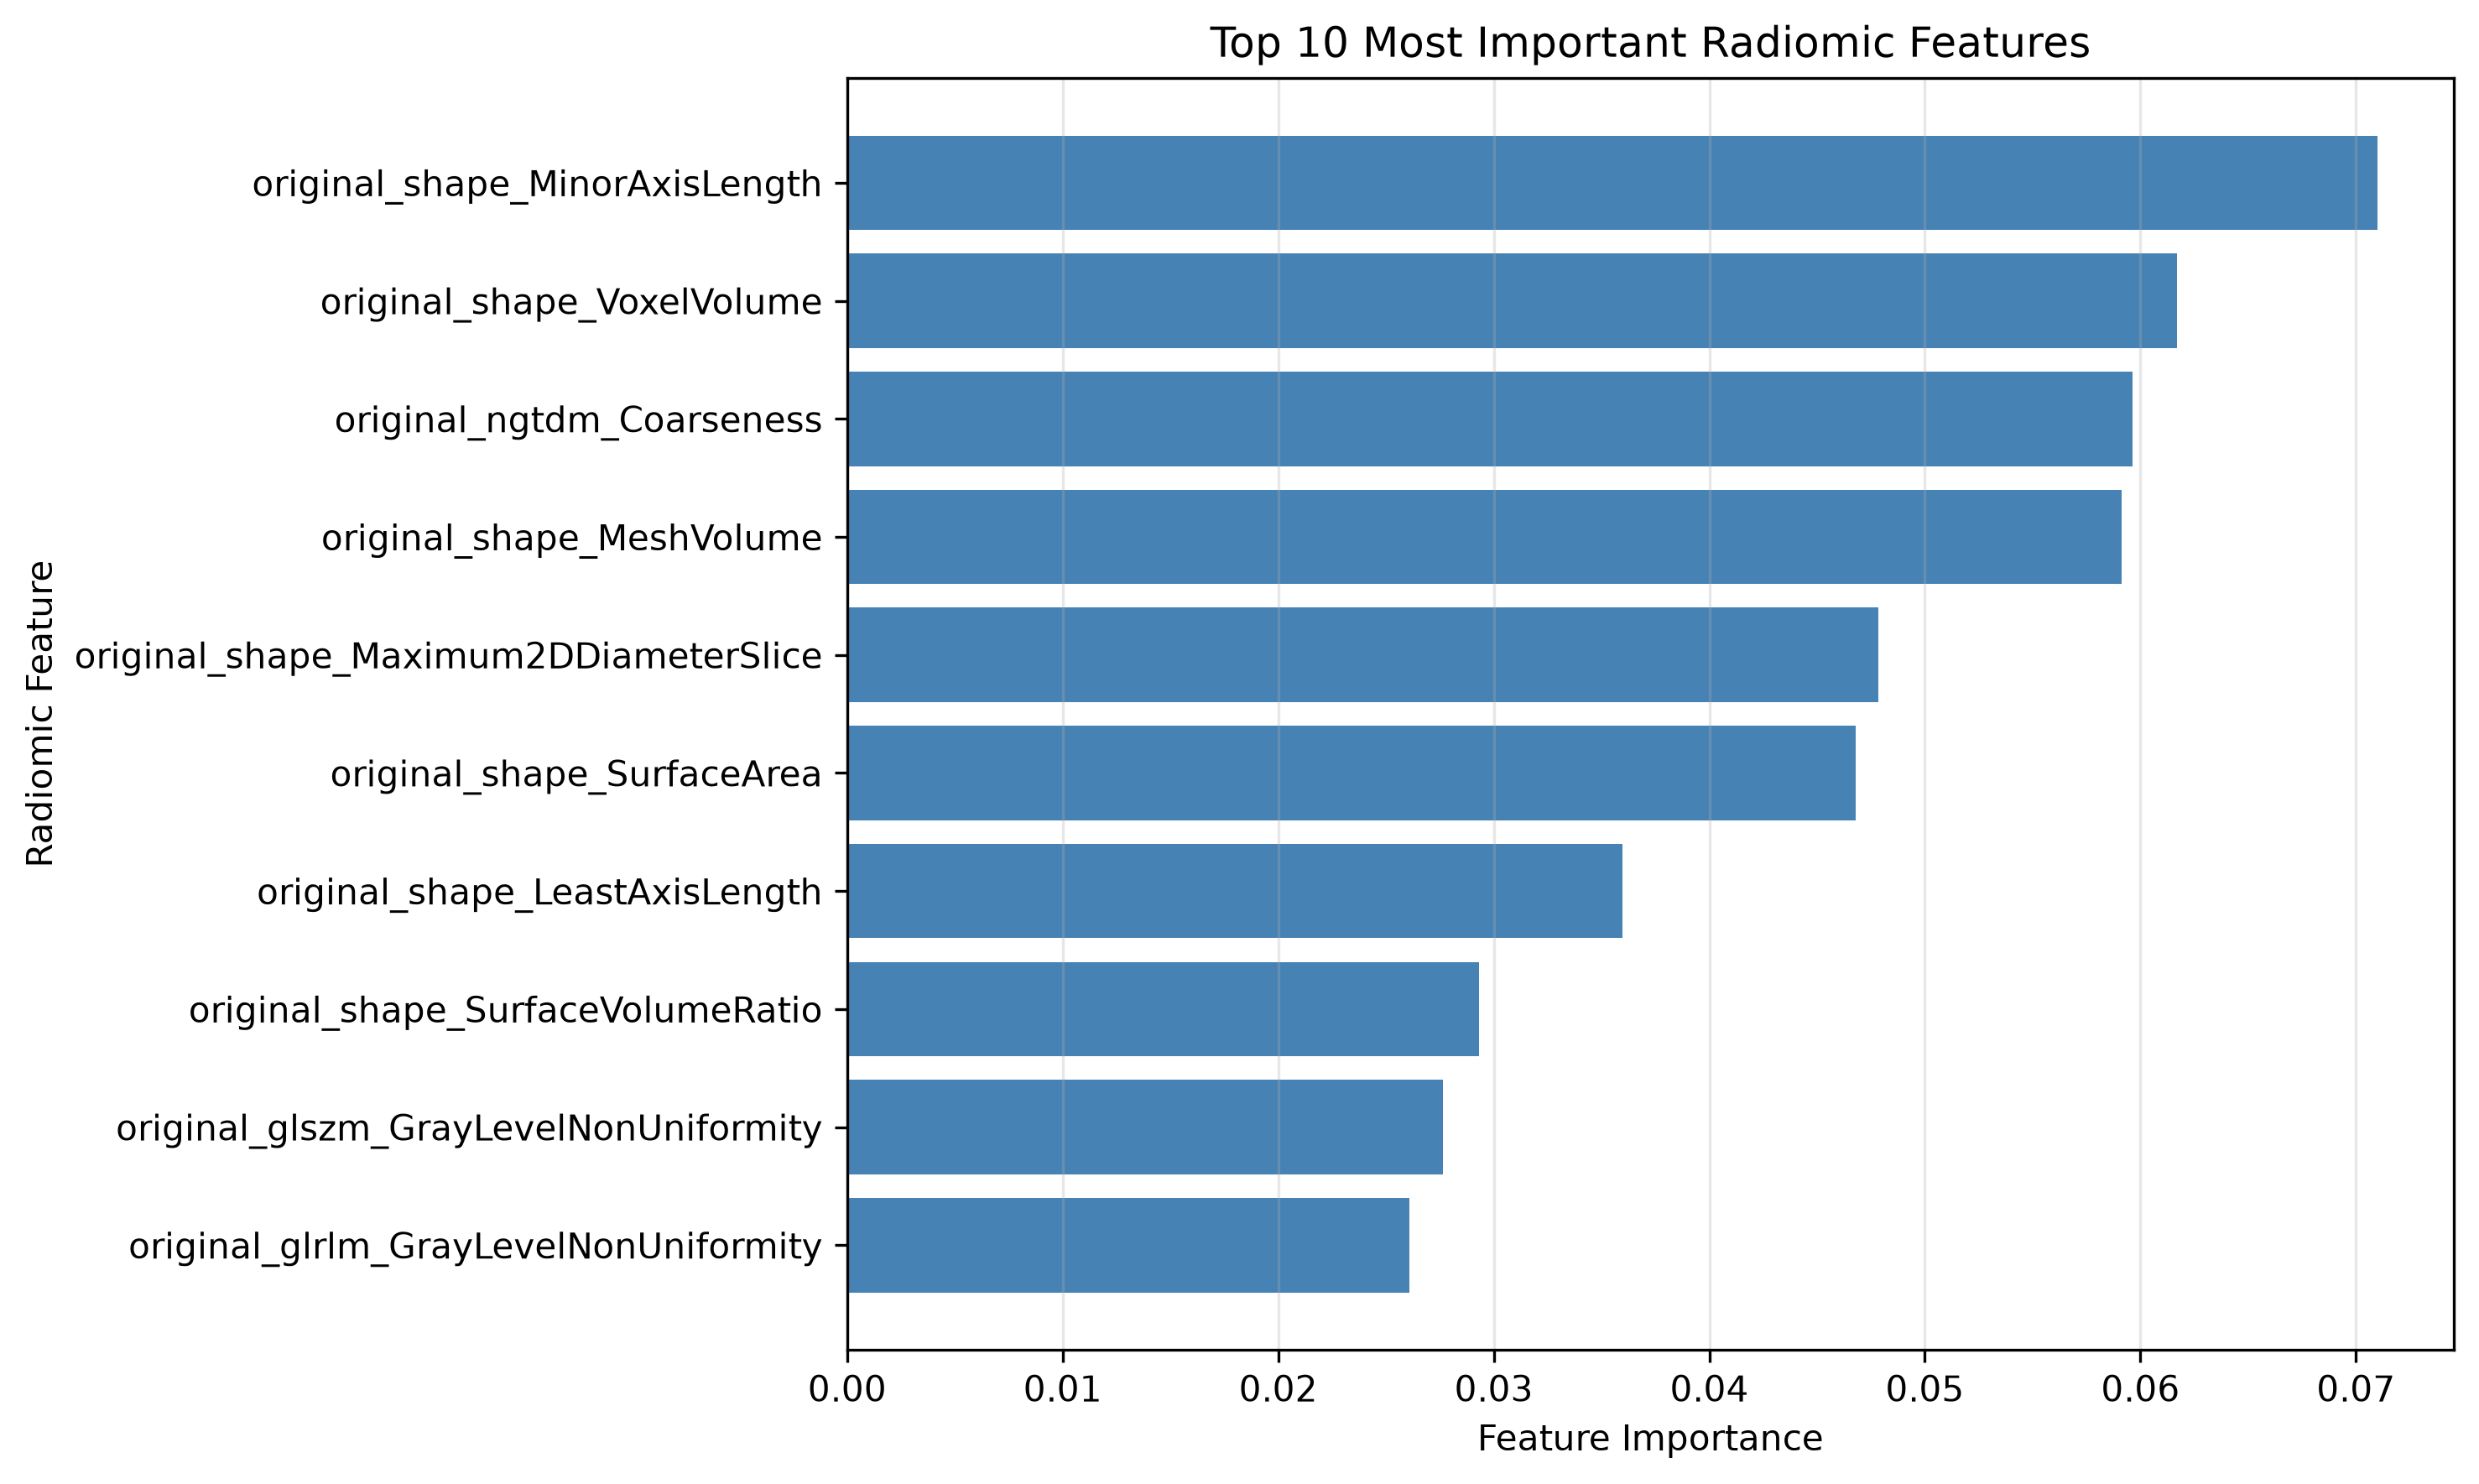

In [12]:
patient_ids = test.patient_id.to_numpy()
labels = test[target].to_numpy()
patients = np.unique(patient_ids)
positions = {patient: np.flatnonzero(patient_ids == patient) for patient in patients}
rng = np.random.default_rng(42)
test_draws = []
for _ in range(1000):
    sampled = rng.choice(patients, len(patients), replace=True)
    indices = np.concatenate([positions[patient] for patient in sampled])
    if np.unique(labels[indices]).size == 2:
        test_draws.append(metrics(labels[indices], rf_test[0][indices], rf_test[1][indices]))
intervals = pd.DataFrame(test_draws).quantile([0.025, 0.975]).T
intervals.columns = ["Reproduced lower", "Reproduced upper"]
display(intervals.join(reference_test[["CI Lower", "CI Upper"]]).round(3))

comparison = pd.read_csv(results_dir / "rf_svm_bootstrap_comparison.csv")
display(comparison[["Metric", "Difference", "Difference CI Lower", "Difference CI Upper"]].round(3))
for name in ("rf_optimization_comparison", "svm_optimization_comparison", "svm_nested_validation"):
    print(name.replace("_", " "))
    display(pd.read_csv(results_dir / f"{name}.csv").round(3))

early_errors = pd.read_csv(results_dir / "classification_error_analysis.csv")
print("Earlier 793/200 protocol")
for model, column in (("Random Forest", "rf_prediction"), ("SVM", "svm_prediction")):
    print(model, confusion_matrix(early_errors[target], early_errors[column], labels=[0, 1]).tolist())
display(Image(filename=str(results_dir / "random_forest_feature_importance.png"), width=560))

The team's 95% test intervals were 0.853–0.946 for accuracy and
0.743–0.924 for recall. The paired validation intervals span zero for
all five metrics, so the validation comparison does not establish a
clear advantage for either classifier.

In the earlier grouped cross-validation, the recorded Random Forest
F1 scores were 0.799 for shape, 0.796 for intensity, 0.802 for texture,
and 0.811 for intensity plus texture or all features. The importance
plot comes from the earlier 793-case forest. Several highly ranked
features measure size and shape. Correlated descriptors can share
importance, so the ranking is descriptive of that particular fit.
The original experiments and volume error analysis remain in
`Radiomics.ipynb`. The exploratory Random Forest trained on
793 nodules had a test matrix of [[124, 7], [11, 58]], whereas the selected
595-case model has [[122, 9], [11, 58]]. Both used the same 200 test cases.

These experiments quantify agreement with the course's voting labels for
pre-identified nodules. Prior inspection of the test cases and the absence
of independent pathology outcomes limit the interpretation of the scores.